# Avance 2 - Ingeniería de características

## Proyecto Integrador
### ThreatLLM: Clasificación de Ciberataques mediante Modelos de Lenguaje

**Equipo 55**

**Integrantes**
- Ada Jimena Vargas Aguirre — A01701619
- Edson Garduño Nolasco — A01795770
- Irving Alan García Zapata — A01796793

**Asesor:** Dr. Víctor Munguía

---

# Fase "Preparación de datos" de CRISP-ML(Q), aplicada al pipeline de ThreatLLM

**Objetivos de esta fase** (según las instrucciones de la actividad):

- **2.3** Crear nuevas características para mejorar el rendimiento de los modelos.
- **2.4** Mitigar el riesgo de características sesgadas y acelerar la convergencia de algunos algoritmos.

Este notebook continúa el trabajo del Avance 1 (fase de comprensión de datos y preprocesamiento de CRISP-ML(Q)). Mientras ese trabajo **describió** las
variables del pipeline (distribución, duplicados, imputación, limpieza), este notebook las
**transforma** en características listas para un modelo de aprendizaje automático, aplicando y
justificando, sobre los datos reales del proyecto (no datos sintéticos de ejemplo):

1. **Generación de nuevas características** — sobre `sentence_classification`,
   `attack-pattern-matching-gt` y las variables derivadas del propio pipeline (Etapas 3-6).
2. **Discretización / binning.**
3. **Codificación** (ordinal, one-hot).
4. **Escalamiento** (estandarización, min-max).
5. **Transformación** (logarítmica, Yeo-Johnson).
6. **Selección de características** — umbral de varianza, correlación, Chi-cuadrado, ANOVA.
7. **Extracción de características** — PCA / TruncatedSVD, Análisis Factorial.
8. **Conclusiones de la fase de Preparación de Datos**, en el contexto de la metodología CRISP-ML(Q).

Todo el código de este notebook se ejecutó contra los datos verificados del pipeline
(`data/ladder/sentence_classification`, `data/attack_pattern/attack-pattern-matching-gt.csv` ya
corregido, y las variables producidas por las Etapas 1-6 del pipeline).

Cuando una técnica no mejora las cosas tanto como se esperaría (por ejemplo, PCA sobre TF-IDF en la sección 4.5), el notebook lo documenta explícitamente.

**Alcance.** `entity_extraction` aporta 2,058 spans de ataque al conjunto de entrenamiento reforzado del
clasificador (Parte 3), pero no recibe características propias en este avance: sus unidades son tokens con
etiquetas IOB (1,800 oraciones, 39,034 tokens) y la tarea de etiquetado de secuencias consume el token y su
contexto, no medidas agregadas por oración. La ingeniería de características se concentra en los conjuntos que
alimentan los modelos del pipeline (`sentence_classification` y `attack-pattern-matching-gt`) y en las variables
derivadas de sus salidas.



## NOTA ACLARATORIA

El uso de modelos como SVM/LogisticRegression, y la mención de avances posteriores a este (como Avance 3, 4 y 5) son referentes a los avances heredados por el equipo anterior a cargo de este proyecto.

Dichos documentos están disponibles en el repositorio del proyecto en la ruta: `ThreatLLM_v2/notebooks/preassigned_notebooks/`

Se toman como punto de partida; las entregas del presente equipo buscan corroborar y/o modificar el pipeline propuesto según sea pertinente.

Las métricas y conteos que se reportan en este notebook se recalculan aquí.




## Carga de datos

In [1]:
# Descomprimir carpeta ZIP con archivos necesarios para la ejecución del notebook
# La carpeta debe cargarse manualmente al entorno de Colab.
!unzip -q -o data.zip
!ls
!ls data

data			fe4_pca.png
data.zip		feat_attack_pattern.csv
fe1_transformacion.png	feat_derivadas.csv
fe2_attack_pattern.png	feat_sentence_classification.csv
fe3_derivadas.png	sample_data
fe4_correlacion.png
attack_pattern	ladder	mitre  reports


## Parte 1 — Ingeniería de características sobre `sentence_classification`

Este es el dataset que alimenta al clasificador de oraciones de ataque de la Etapa 3 del
pipeline (TF-IDF + LogisticRegression/SVM). Antes de generar características nuevas, se
reproducen las Etapas 1 y 2 del pipeline (carga del reporte + vectorización TF-IDF) para tener
disponibles `train_df`, `X_train` y `y_train` en este notebook.

In [2]:
import re
from pathlib import Path
import pandas as pd

# ---------------------------------------------------------------------------
# 1a. Localización portable del reporte de entrada
# ---------------------------------------------------------------------------
def _find_base(*relative_candidates):
    here = Path.cwd()
    search_roots = [here] + list(here.parents)[:4]
    for base in search_roots:
        for rel in relative_candidates:
            p = base / rel
            if p.exists():
                return p
    raise FileNotFoundError(
        f"No se encontró ninguna de estas rutas relativas a {here}: {relative_candidates}"
    )

# NOTA: este es el reporte de Kaspersky Securelist sobre WIRTE/LitePower
# (173 líneas), tomado directamente del repositorio oficial de LADDER
# (github.com/aiforsec/LADDER, notebooks/litepower.txt) — no la paráfrasis corta usada
# en una versión anterior de esta etapa.
REPORT_PATH = _find_base("data/reports/litepower.txt", "reports/litepower.txt")
raw_report = REPORT_PATH.read_text(encoding="utf-8")

print(f"Reporte cargado desde: {REPORT_PATH}")
print(f"Longitud: {len(raw_report)} caracteres, {len(raw_report.splitlines())} líneas de texto crudo")

# ---------------------------------------------------------------------------
# 1b. Segmentación del reporte en oraciones (misma función que antes)
# ---------------------------------------------------------------------------
def split_into_sentences(text: str) -> list:
    parts = re.split(r"(?<=[.!?])\s+|\n+", text.strip())
    return [p.strip() for p in parts if p.strip()]

raw_sentences = split_into_sentences(raw_report)
print(f"\nOraciones segmentadas (sin filtrar): {len(raw_sentences)}")

# ---------------------------------------------------------------------------
# 1c. Un reporte real (no un demo corto) trae ruido estructural: encabezados de
#     sección, pies de tabla repetidos, fragmentos de código PowerShell cortados
#     línea por línea. Se aplica un filtro simple y documentado — descartar
#     fragmentos de 3 palabras o menos — no para "arreglar" la segmentación,
#     sino para no alimentar a las etapas siguientes con basura obvia.
# ---------------------------------------------------------------------------
ruido_ejemplos = [s for s in raw_sentences if len(s.split()) <= 3][:8]
report_sentences = [s for s in raw_sentences if len(s.split()) > 3]
print(f"Tras descartar fragmentos de ≤3 palabras: {len(report_sentences)} oraciones "
      f"({len(raw_sentences) - len(report_sentences)} descartadas)")
print(f"Ejemplos descartados: {ruido_ejemplos}")

report_df = pd.DataFrame({
    "sentence_id": range(len(report_sentences)),
    "text": report_sentences,
})

# ---------------------------------------------------------------------------
# 1d. Verificación de los datos crudos de LADDER que alimentarán las
#     Etapas 2 y 3 (ya subidos por el equipo; se confirma que son los
#     splits oficiales completos)
# ---------------------------------------------------------------------------
sc_dir = _find_base("data/ladder/sentence_classification/train.csv").parent

LADDER_SC_EXPECTED = {"train": 2214, "dev": 568, "test": 662}

print("\nVerificación de integridad — LADDER sentence_classification (splits oficiales):")
sc_splits = {}
for split, expected_n in LADDER_SC_EXPECTED.items():
    df_split = pd.read_csv(sc_dir / f"{split}.csv", sep="\t")
    sc_splits[split] = df_split
    balance = df_split["label"].value_counts().sort_index().to_dict()
    check = "OK" if len(df_split) == expected_n else "MISMATCH"
    print(f"  {split:5s}: {len(df_split):4d} filas (esperado {expected_n}) [{check}] | "
          f"labels: {balance}")

print(f"\nPrimeras 5 oraciones del reporte, ya filtradas:")
print(report_df.head(5).to_string(index=False))


Reporte cargado desde: /content/data/reports/litepower.txt
Longitud: 16243 caracteres, 173 líneas de texto crudo

Oraciones segmentadas (sin filtrar): 172
Tras descartar fragmentos de ≤3 palabras: 124 oraciones (48 descartadas)
Ejemplos descartados: ['Overview', 'Contact: intelreports@kaspersky.com”', 'Ferocious dropper', 'LitePower stager', 'LitePower PowerShell implant', 'LitePower PowerShell implant', '1', 'Command\tDescription']

Verificación de integridad — LADDER sentence_classification (splits oficiales):
  train: 2214 filas (esperado 2214) [OK] | labels: {0: 1107, 1: 1107}
  dev  :  568 filas (esperado 568) [OK] | labels: {0: 284, 1: 284}
  test :  662 filas (esperado 662) [OK] | labels: {0: 331, 1: 331}

Primeras 5 oraciones del reporte, ya filtradas:
 sentence_id                                                                                                                                                                                                                         

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

# ---------------------------------------------------------------------------
# 2a. Vectorizador TF-IDF — misma configuración ya validada en Avance 3 y
#     Avance 4 (celda "1.4 Vectorización TF-IDF").
# ---------------------------------------------------------------------------
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10_000,
    sublinear_tf=True,
    min_df=2,
    strip_accents="unicode",
)

train_df = sc_splits["train"]
dev_df = sc_splits["dev"]
test_df = sc_splits["test"]

X_train = tfidf.fit_transform(train_df["text"])
X_dev = tfidf.transform(dev_df["text"])
X_test = tfidf.transform(test_df["text"])

y_train = train_df["label"].to_numpy()
y_dev = dev_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print(f"Vocabulario aprendido: {len(tfidf.vocabulary_)} términos (tope max_features={tfidf.max_features})")
print(f"X_train: {X_train.shape}  (filas=oraciones de train, columnas=términos del vocabulario)")
print(f"X_dev:   {X_dev.shape}")
print(f"X_test:  {X_test.shape}")
print(f"Densidad de X_train: {X_train.nnz / (X_train.shape[0] * X_train.shape[1]):.4%} de celdas distintas de cero")

# ---------------------------------------------------------------------------
# 2b. Proyectar las oraciones del reporte (salida de la Etapa 1, ya el reporte
#     real y completo de WIRTE/LitePower, 124 oraciones tras el filtro) al
#     MISMO espacio vectorial — el reporte nunca participa en el ajuste.
# ---------------------------------------------------------------------------
X_report = tfidf.transform(report_df["text"])
print(f"\nX_report: {X_report.shape}  (124 oraciones del reporte real de WIRTE/LitePower, "
      f"proyectadas al vocabulario de LADDER)")

# ---------------------------------------------------------------------------
# 2c. Ejemplo concreto: qué términos "ve" el vectorizador en una oración real
#     del reporte, y con qué peso
# ---------------------------------------------------------------------------
example_idx = 83  # "These C2 domains were occasionally behind CloudFlare to obscure the real C2 IP address."
example_text = report_df.loc[example_idx, "text"]
example_vec = X_report[example_idx]

feature_names = tfidf.get_feature_names_out()
nonzero_cols = example_vec.nonzero()[1]
weights = [(feature_names[c], round(example_vec[0, c], 4)) for c in nonzero_cols]
weights.sort(key=lambda t: t[1], reverse=True)

print(f"\nOración de ejemplo: \"{example_text}\"")
print(f"Términos con peso TF-IDF distinto de cero ({len(weights)} de {len(feature_names)} posibles), ordenados de mayor a menor peso:")
for term, w in weights[:12]:
    print(f"  {w:.4f}  {term!r}")

# ---------------------------------------------------------------------------
# 2d. Palabras de esa oración que el vectorizador NO reconoce (fuera del
#     vocabulario aprendido en LADDER train)
# ---------------------------------------------------------------------------
import re as _re
vocab_set = set(tfidf.vocabulary_.keys())
example_tokens = set(_re.findall(r"[a-záéíóúñ]+", example_text.lower()))
oov_tokens = sorted(t for t in example_tokens if t not in vocab_set and len(t) > 2)
print(f"\nPalabras de esa misma oración que NO están en el vocabulario de LADDER (peso 0, invisibles para el modelo): {oov_tokens}")


Vocabulario aprendido: 7715 términos (tope max_features=10000)
X_train: (2214, 7715)  (filas=oraciones de train, columnas=términos del vocabulario)
X_dev:   (568, 7715)
X_test:  (662, 7715)
Densidad de X_train: 0.3225% de celdas distintas de cero

X_report: (124, 7715)  (124 oraciones del reporte real de WIRTE/LitePower, proyectadas al vocabulario de LADDER)

Oración de ejemplo: "These C2 domains were occasionally behind CloudFlare to obscure the real C2 IP address."
Términos con peso TF-IDF distinto de cero (13 de 7715 posibles), ordenados de mayor a menor peso:
  0.3632  'obscure'
  0.3632  'to obscure'
  0.3602  'c2'
  0.3301  'ip address'
  0.3012  'domains'
  0.2776  'ip'
  0.2703  'address'
  0.2703  'real'
  0.2583  'behind'
  0.2318  'these'
  0.2260  'were'
  0.0849  'to'

Palabras de esa misma oración que NO están en el vocabulario de LADDER (peso 0, invisibles para el modelo): ['cloudflare', 'occasionally']


### 1.1 – 1.5 Generación, discretización, codificación, escalamiento y transformación

=== 1.1 Generación de nuevas características — sentence_classification ===
Más allá de TF-IDF (que ya captura la presencia/peso de términos), se construyen características numéricas a nivel de oración que resumen propiedades estructurales y léxicas del texto. Estas son útiles porque son independientes del vocabulario aprendido y no sufren el problema de palabras fuera-de-vocabulario (OOV) documentado en el notebook de análisis de variables.

8 características numéricas nuevas generadas: ['n_chars', 'n_words', 'avg_word_len', 'n_punct', 'n_digits', 'upper_ratio', 'lexical_diversity', 'n_keywords']

Estadísticas descriptivas de las características generadas (antes de escalar/transformar):
        n_chars   n_words  avg_word_len   n_punct  n_digits  upper_ratio  lexical_diversity  n_keywords
count  2214.000  2214.000      2214.000  2214.000  2214.000     2214.000           2214.000    2214.000
mean    117.408    18.333         7.089     2.546     1.111        0.046              0.921     

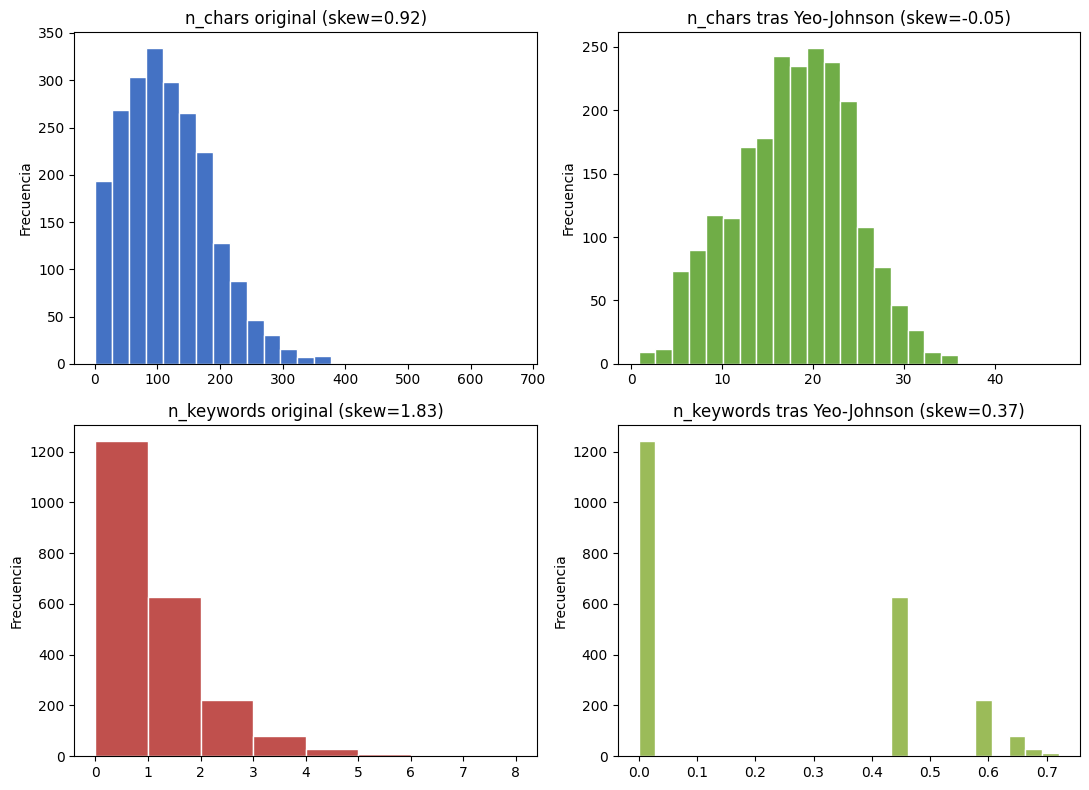


[Figura guardada: distribución antes/después de Yeo-Johnson para n_chars y n_keywords]

Tabla de características de sentence_classification (train) guardada: 2214 filas x 44 columnas.


In [4]:
import os
os.environ["MPLCONFIGDIR"] = "/tmp/mpl-fe-threatllm"
import warnings
warnings.filterwarnings("ignore")
import re
import numpy as np
import pandas as pd
from scipy.stats import skew, yeojohnson
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer, OneHotEncoder
import matplotlib
import matplotlib.pyplot as plt

# NOTA: este script se ejecuta DESPUÉS de correr en el mismo namespace etapa1_code.py
# y etapa2_code.py del pipeline, de las que reutiliza train_df (texto + label de
# sentence_classification) y X_train/tfidf (representación TF-IDF ya ajustada).

print("=== 1.1 Generación de nuevas características — sentence_classification ===")
print(
    "Más allá de TF-IDF (que ya captura la presencia/peso de términos), se construyen "
    "características numéricas a nivel de oración que resumen propiedades estructurales y "
    "léxicas del texto. Estas son útiles porque son independientes del vocabulario aprendido y no "
    "sufren el problema de palabras fuera-de-vocabulario (OOV) documentado en el notebook de "
    "análisis de variables."
)

feat_df = train_df.copy().reset_index(drop=True)


def contar_puntuacion(t):
    return sum(1 for ch in t if ch in ".,;:!?-()[]\"'")


KEYWORDS = {
    "malware", "attacker", "exploit", "inject", "payload", "encrypt", "root", "permission",
    "steal", "hide", "command", "c2", "server", "download", "execute", "persistence",
    "escalate", "phishing", "credential", "backdoor", "exfiltrate", "victim", "device",
    "access", "install", "vulnerability", "privilege",
}


def contar_keywords(t):
    tokens = re.findall(r"[a-záéíóúñ]+", t.lower())
    return sum(1 for tok in tokens if tok in KEYWORDS)


feat_df["n_chars"] = feat_df["text"].str.len()
feat_df["n_words"] = feat_df["text"].str.split().apply(len)
feat_df["avg_word_len"] = feat_df["n_chars"] / feat_df["n_words"]
feat_df["n_punct"] = feat_df["text"].apply(contar_puntuacion)
feat_df["n_digits"] = feat_df["text"].apply(lambda t: sum(ch.isdigit() for ch in t))
feat_df["upper_ratio"] = feat_df["text"].apply(
    lambda t: sum(1 for ch in t if ch.isupper()) / max(len(t), 1)
)
feat_df["lexical_diversity"] = feat_df["text"].apply(
    lambda t: len(set(re.findall(r"[a-záéíóúñ]+", t.lower())))
    / max(len(re.findall(r"[a-záéíóúñ]+", t.lower())), 1)
)
feat_df["n_keywords"] = feat_df["text"].apply(contar_keywords)

NUM_FEATS = ["n_chars", "n_words", "avg_word_len", "n_punct", "n_digits",
             "upper_ratio", "lexical_diversity", "n_keywords"]

print(f"\n{len(NUM_FEATS)} características numéricas nuevas generadas: {NUM_FEATS}")
print("\nEstadísticas descriptivas de las características generadas (antes de escalar/transformar):")
print(feat_df[NUM_FEATS].describe().round(3).to_string())

print("\nCorrelación punto-biserial de cada característica nueva con la etiqueta (label):")
for c in NUM_FEATS:
    corr = feat_df[c].corr(feat_df["label"])
    print(f"  {c:18s}: r = {corr:+.4f}")

print(
    "\nJustificación: n_keywords es la característica más correlacionada con la etiqueta (r=+0.30), "
    "seguida de n_digits (r=-0.15) y n_chars (r=+0.14); el resto es débil (|r| <= 0.13). Las "
    "correlaciones son modestas, por lo que estas características se consideran señales complementarias a "
    "TF-IDF y no predictores fuertes. Cabe destacar 2 aclaraciones : (1) la lista KEYWORDS (27 términos) fue definida "
    "manualmente por el equipo con criterio de dominio, así que la asociación de n_keywords con la etiqueta "
    "es en parte esperable por construcción y no debe leerse como evidencia independiente; (2) el conteo "
    "busca coincidencias exactas de token (sin lematizar), por lo que subestima variantes como 'devices' o "
    "'stealing', y 'c2' no puede coincidir porque el tokenizador separa letras de dígitos."
)

# ---------------------------------------------------------------------------
# 1.2 Discretización / binning
# ---------------------------------------------------------------------------
print("\n=== 1.2 Discretización (binning) de longitud de oración ===")
feat_df["longitud_categoria"] = pd.qcut(
    feat_df["n_words"], q=3, labels=["corta", "media", "larga"]
)
print("Bins por cuantiles (terciles) sobre n_words — se usan cuantiles en vez de ancho fijo "
      "porque la distribución de longitud no es uniforme (ver EDA del Avance 1):")
print(feat_df["longitud_categoria"].value_counts().sort_index().to_string())

print("\nProporción de oraciones de ataque (label=1) por categoría de longitud:")
tab = feat_df.groupby("longitud_categoria")["label"].mean().round(3)
print(tab.to_string())
print(
    "\nJustificación: la proporción de label=1 es casi igual en las oraciones cortas y medias (0.466 y 0.467) y "
    "sube solo en las largas (0.567); es decir, la relación con la longitud no es lineal, lo que respalda tratar "
    "la longitud como categoría: la categoría discretizada aporta una señal que un escalamiento lineal de "
    "n_words no captura directamente. Una posible explicación es que las oraciones de ataque (TTP) largas suelen "
    "describir una acción completa con más detalle, pero esto es una hipótesis, no algo que el experimento pruebe."
)

# ---------------------------------------------------------------------------
# 1.3 Codificación
# ---------------------------------------------------------------------------
print("\n=== 1.3 Codificación — longitud_categoria (nominal) ===")
ohe = OneHotEncoder(sparse_output=False, dtype=int)
onehot_cols = ohe.fit_transform(feat_df[["longitud_categoria"]])
onehot_df = pd.DataFrame(
    onehot_cols, columns=[f"long_{c}" for c in ohe.categories_[0]]
)
print(f"One-hot encoding aplicado: {onehot_df.shape[1]} columnas binarias nuevas "
      f"({list(onehot_df.columns)})")
print(onehot_df.head(3).to_string(index=False))
print(
    "\nJustificación de one-hot (en vez de ordinal): aunque 'corta < media < larga' tiene un orden "
    "natural, no se asume que el efecto de la longitud sobre la probabilidad de ataque sea lineal ni "
    "monótono; one-hot permite que cada categoría tenga su propio peso y evita imponer una distancia "
    "numérica arbitraria (p. ej., que 'larga' sea exactamente 2x 'corta') a los modelos lineales del "
    "pipeline. Esto difiere de severity_category (Parte 3), donde el orden SÍ es monótono respecto al "
    "puntaje CTS que la define. Nota: se conservan las 3 columnas (sin drop='first') porque aquí el "
    "one-hot se usa de forma exploratoria; en un modelo lineal sin regularización habría que omitir una "
    "categoría para evitar la trampa de la variable ficticia (colinealidad perfecta)."
)
print("La etiqueta 'label' (0=no-ataque, 1=ataque) ya viene codificada como binaria en el "
      "dataset oficial de LADDER — no requiere transformación adicional.")

feat_df = pd.concat([feat_df, onehot_df], axis=1)

# ---------------------------------------------------------------------------
# 1.4 Escalamiento
# ---------------------------------------------------------------------------
print("\n=== 1.4 Escalamiento de las características numéricas ===")
print(
    "Las 8 características generadas tienen escalas muy distintas (p. ej., n_chars llega a "
    "varios cientos, mientras que lexical_diversity y upper_ratio están acotadas en [0,1]). Sin "
    "escalar, un clasificador basado en distancia o en descenso de gradiente (LogisticRegression, "
    "SVM; que son los mismos algoritmos de la Etapa 3) le daría implícitamente más peso a n_chars solo "
    "por su magnitud, y convergería más lento porque el gradiente se dominaría por esa escala. "
    "Esto es exactamente el riesgo de 'características sesgadas' y de convergencia lenta que "
    "pide mitigar esta fase."
)

raw_vals = feat_df[NUM_FEATS].to_numpy()

scaler_std = StandardScaler()
scaled_std = scaler_std.fit_transform(raw_vals)
scaled_std_df = pd.DataFrame(scaled_std, columns=[f"{c}_std" for c in NUM_FEATS])

scaler_mm = MinMaxScaler()
scaled_mm = scaler_mm.fit_transform(raw_vals)
scaled_mm_df = pd.DataFrame(scaled_mm, columns=[f"{c}_mm" for c in NUM_FEATS])

print("\nRango (min, max) ANTES de escalar:")
print(feat_df[NUM_FEATS].agg(["min", "max"]).round(3).to_string())
print("\nRango (min, max) DESPUÉS de StandardScaler (media 0, desv. 1):")
print(scaled_std_df.agg(["mean", "std"]).round(3).to_string())
print("\nRango (min, max) DESPUÉS de MinMaxScaler ([0,1]):")
print(scaled_mm_df.agg(["min", "max"]).round(3).to_string())

print(
    "\nSe elige StandardScaler como escalamiento principal para alimentar a LogisticRegression/"
    "SVM (asumen o se benefician de features centradas, y no son sensibles a un límite [0,1] "
    "estricto); MinMaxScaler se deja como alternativa documentada para el caso en que se quisiera "
    "alimentar un algoritmo que exige entradas no negativas acotadas (p. ej., ciertas redes con "
    "activaciones sigmoides en la primera capa)."
)

feat_df = pd.concat([feat_df, scaled_std_df, scaled_mm_df], axis=1)

# ---------------------------------------------------------------------------
# 1.5 Transformación
# ---------------------------------------------------------------------------
print("\n=== 1.5 Transformación de características sesgadas ===")
skew_before = feat_df[NUM_FEATS].apply(lambda c: skew(c))
print("Sesgo (skewness) de cada característica, antes de transformar:")
print(skew_before.round(3).to_string())

sesgadas = skew_before[skew_before.abs() > 0.75].index.tolist()
print(f"\nCaracterísticas con sesgo relevante (|skew| > 0.75): {sesgadas}")
print(
    "Justificación del umbral: 0.75 es un criterio práctico común (no hay una regla universal) "
    "para distinguir una distribución aproximadamente simétrica de una con cola larga que puede "
    "perjudicar a modelos lineales o basados en distancia."
)

transformadas = {}
for c in sesgadas:
    log_vals = np.log1p(feat_df[c].clip(lower=0))
    yj_vals, lam = yeojohnson(feat_df[c].to_numpy())
    transformadas[c] = {
        "log1p_skew": round(skew(log_vals), 3),
        "yeojohnson_skew": round(skew(yj_vals), 3),
        "yeojohnson_lambda": round(lam, 3),
    }
    feat_df[f"{c}_log1p"] = log_vals
    feat_df[f"{c}_yj"] = yj_vals

print("\nComparación de sesgo tras log1p vs. Yeo-Johnson (elige el método, no solo la fórmula):")
for c, info in transformadas.items():
    print(f"  {c:12s}: sesgo original={skew_before[c]:+.3f} | log1p={info['log1p_skew']:+.3f} "
          f"| Yeo-Johnson (λ={info['yeojohnson_lambda']})={info['yeojohnson_skew']:+.3f}")

print(
    "\nSe prefiere Yeo-Johnson sobre log1p como transformación final: log1p asume que grandes "
    "valores deben comprimirse de forma fija (logarítmica), mientras que Yeo-Johnson estima el "
    "parámetro λ que minimiza el sesgo para cada característica específica (y, a diferencia de "
    "Box-Cox, admite valores 0 sin necesitar un desplazamiento manual, relevante aquí porque "
    "n_digits y n_keywords valen 0 en muchas oraciones)."
)

print(
    "\nNota honesta: Yeo-Johnson reduce el sesgo en las 7 características, pero no lo elimina en todas. "
    "Persisten sesgos residuales con |skew| > 0.75 en: "
    + str({c: round(float(i["yeojohnson_skew"]), 2) for c, i in transformadas.items() if abs(i["yeojohnson_skew"]) > 0.75})
    + " (variables con muchos ceros y valores extremos). Además, hay valores de lambda extremos en: "
    + str({c: round(float(i["yeojohnson_lambda"]), 1) for c, i in transformadas.items() if abs(i["yeojohnson_lambda"]) > 5})
    + ", lo que indica que la transformación es inestable para esas variables y sus resultados deben "
    "interpretarse con cautela. Los parámetros del escalador y de Yeo-Johnson se estiman solo con train; "
    "en dev/test se aplicarían con transform (sin reajustar), como se hace en el experimento 4.7."
)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].hist(feat_df["n_chars"], bins=25, color="#4472C4", edgecolor="white")
axes[0, 0].set_title(f"n_chars original (skew={skew_before['n_chars']:.2f})")
axes[0, 1].hist(feat_df["n_chars_yj"], bins=25, color="#70AD47", edgecolor="white")
axes[0, 1].set_title(f"n_chars tras Yeo-Johnson (skew={skew(feat_df['n_chars_yj']):.2f})")
axes[1, 0].hist(feat_df["n_keywords"], bins=range(0, int(feat_df["n_keywords"].max()) + 2),
                 color="#C0504D", edgecolor="white")
axes[1, 0].set_title(f"n_keywords original (skew={skew_before['n_keywords']:.2f})")
axes[1, 1].hist(feat_df["n_keywords_yj"], bins=25, color="#9BBB59", edgecolor="white")
axes[1, 1].set_title(f"n_keywords tras Yeo-Johnson (skew={skew(feat_df['n_keywords_yj']):.2f})")
for ax in axes.flat:
    ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.savefig("fe1_transformacion.png", dpi=110)
plt.show()
print("\n[Figura guardada: distribución antes/después de Yeo-Johnson para n_chars y n_keywords]")

feat_df.to_csv("feat_sentence_classification.csv", index=False)
print(f"\nTabla de características de sentence_classification (train) guardada: "
      f"{feat_df.shape[0]} filas x {feat_df.shape[1]} columnas.")


**Síntesis de la Parte 1.**

Se generaron 8 características numéricas a partir del texto crudo (longitud,
puntuación, dígitos, mayúsculas, diversidad léxica y conteo de palabras clave), complementarias a TF-IDF
porque no dependen del vocabulario aprendido.

`n_keywords` es la más correlacionada con la etiqueta
(r=+0.30), seguida de `n_digits` (-0.15) y `n_chars` (+0.14); las correlaciones son modestas, y `n_keywords`
usa una lista definida por el equipo, por lo que su asociación es en parte esperable por construcción.

La longitud se discretizó en terciles y se codificó con one-hot, sin asumir un efecto lineal o monótono de la longitud sobre la probabilidad de ataque.

Las 8 características se escalaron con `StandardScaler` (ajustado
solo con train): sin escalar, `n_chars` (rango 1-672) dominaría por magnitud el gradiente de un modelo lineal
frente a `lexical_diversity` (rango 0-1), el riesgo de características sesgadas y de convergencia lenta del
objetivo 2.4. Siete de las ocho mostraron sesgo relevante (|skew| > 0.75) y se corrigieron con
Yeo-Johnson, que lo redujo en todas pero no lo eliminó en `n_digits` (+1.60) ni en `avg_word_len` (-1.39), y
estimó valores de lambda extremos en `upper_ratio` y `lexical_diversity`; esas transformaciones deben
interpretarse con cautela.



> Nota sobre el gráfico

`n_keywords` toma solo valores enteros, por lo que Yeo-Johnson comprime la cola y reduce su sesgo, pero no suaviza la distribución. Es decir, los valores transformados siguen siendo discretos y con un gran volumen en cero.




## Parte 2 — Ingeniería de características sobre `attack-pattern-matching-gt`

Dataset de 81 descripciones de procedimiento (texto) con su familia de malware y su técnica MITRE asociada.
Se usa la versión corregida del archivo (19 de las 81 etiquetas MITRE se ajustaron respecto al original; el
detalle está en `attack-pattern-matching-gt_auditoria.csv`). Aquí la ingeniería de características se enfoca
en la variable categórica `malware` y en la variable objetivo `label`, cuya alta cardinalidad (32 técnicas
sobre solo 81 filas) es en sí misma una característica a tener en cuenta en la fase de modelado.


=== 2.1 Generación de nuevas características — attack-pattern-matching-gt ===
Se agrega n_words/n_chars (longitud de la descripción de procedimiento) por la misma razón que en sentence_classification: son señales independientes del vocabulario que complementan cualquier representación TF-IDF que se construya sobre 'text' para un futuro clasificador de técnica.
       n_words  n_chars
count    81.00    81.00
mean      8.37    54.07
std       5.31    31.34
min       2.00    15.00
25%       4.00    29.00
50%       7.00    46.00
75%      11.00    69.00
max      24.00   137.00

Se agrega también 'malware_freq': cuántas muestras tiene esa familia de malware en el dataset. Es una característica de frecuencia que resume la prevalencia de la familia sin necesitar una codificación de alta cardinalidad.
   malware  malware_freq
  Cerberus            13
      Ginp            12
ViceLeaker             7
 SpyDealer             7
 Skygofree             6
RCSAndroid             6

Nota: malware_freq e

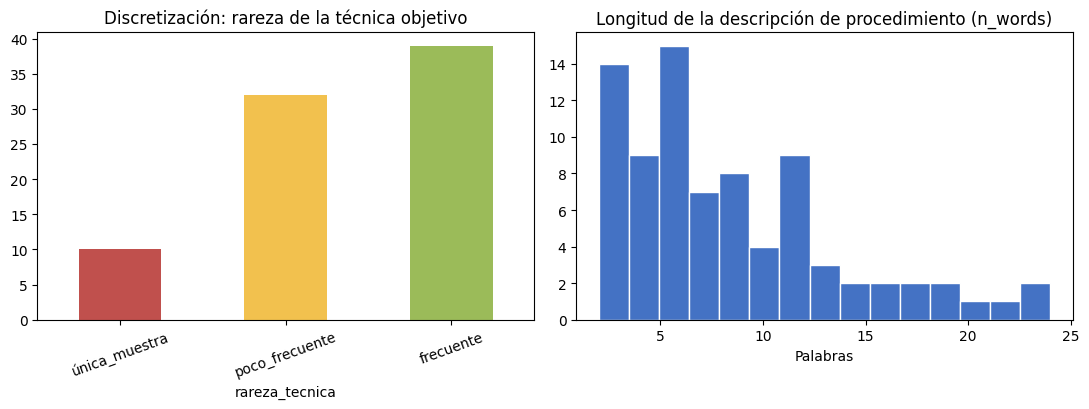


[Figura guardada: rareza de técnica (discretización) + distribución de longitud]

Tabla de características de attack-pattern-matching-gt guardada: 81 filas x 27 columnas.


In [5]:
import os
os.environ["MPLCONFIGDIR"] = "/tmp/mpl-fe-threatllm"
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
import matplotlib
import matplotlib.pyplot as plt


def _find_base(*relative_candidates):
    here = Path.cwd()
    search_roots = [here] + list(here.parents)[:4]
    for base in search_roots:
        for rel in relative_candidates:
            p = base / rel
            if p.exists():
                return p
    raise FileNotFoundError(f"No se encontró ninguna de estas rutas relativas a {here}: {relative_candidates}")


AP_PATH = _find_base("data/attack_pattern/attack-pattern-matching-gt.csv")
ap_df = pd.read_csv(AP_PATH)

print("=== 2.1 Generación de nuevas características — attack-pattern-matching-gt ===")
ap_df["n_words"] = ap_df["text"].str.split().apply(len)
ap_df["n_chars"] = ap_df["text"].str.len()
print("Se agrega n_words/n_chars (longitud de la descripción de procedimiento) por la misma "
      "razón que en sentence_classification: son señales independientes del vocabulario que "
      "complementan cualquier representación TF-IDF que se construya sobre 'text' para un futuro "
      "clasificador de técnica.")
print(ap_df[["n_words", "n_chars"]].describe().round(2).to_string())

print(
    "\nSe agrega también 'malware_freq': cuántas muestras tiene esa familia de malware en el "
    "dataset. Es una característica de frecuencia que resume la prevalencia de la familia sin "
    "necesitar una codificación de alta cardinalidad."
)
malware_counts = ap_df["malware"].value_counts()
ap_df["malware_freq"] = ap_df["malware"].map(malware_counts)
print(ap_df[["malware", "malware_freq"]].drop_duplicates().sort_values("malware_freq", ascending=False).head(6).to_string(index=False))
print(
    "\nNota: malware_freq es una función de la categoría 'malware' (cada familia siempre tiene el mismo "
    "valor), por lo que equivale a una combinación lineal de las columnas one-hot de 2.2. Se generan ambas "
    "como candidatas; en el modelado debe conservarse una de las dos representaciones (la frecuencia sola, "
    "si se quiere evitar la alta cardinalidad), no ambas."
)

# ---------------------------------------------------------------------------
# 2.2 Codificación
# ---------------------------------------------------------------------------
print("\n=== 2.2 Codificación ===")
n_malware = ap_df["malware"].nunique()
n_label = ap_df["label"].nunique()
print(f"Cardinalidad: 'malware' tiene {n_malware} categorías, 'label' (técnica MITRE) tiene "
      f"{n_label} categorías sobre {len(ap_df)} filas.")

ohe = OneHotEncoder(sparse_output=False, dtype=int)
malware_onehot = ohe.fit_transform(ap_df[["malware"]])
malware_onehot_df = pd.DataFrame(malware_onehot, columns=[f"mw_{c}" for c in ohe.categories_[0]])
print(f"\n'malware' ({n_malware} categorías): se codifica con ONE-HOT -> {malware_onehot_df.shape[1]} "
      f"columnas binarias. Justificación: {n_malware} categorías es manejable (no explota la "
      "dimensionalidad) y 'malware' no tiene un orden natural, así que one-hot es la opción "
      "correcta frente a una codificación ordinal arbitraria.")
print("Nota: se conservan las 19 columnas (sin drop='first'); en un modelo lineal sin regularización "
      "habría que omitir una para evitar colinealidad perfecta.")

print(
    f"\n'label' (técnica MITRE, {n_label} categorías) NO se one-hot-codifica como entrada: es la "
    "variable OBJETIVO de un eventual clasificador de técnica, no una característica predictora. "
    "Para esa variable objetivo basta con un LabelEncoder entero (lo que internamente ya hace "
    "cualquier clasificador de scikit-learn); one-hot aquí solo inflaría memoria sin aportar nada, "
    "porque el objetivo es predicho, no consumido como entrada."
)
ap_df = pd.concat([ap_df, malware_onehot_df], axis=1)

# ---------------------------------------------------------------------------
# 2.3 Discretización
# ---------------------------------------------------------------------------
print("\n=== 2.3 Discretización — rareza de la técnica objetivo ===")
label_counts = ap_df["label"].value_counts()
ap_df["label_freq"] = ap_df["label"].map(label_counts)
ap_df["rareza_tecnica"] = pd.cut(
    ap_df["label_freq"], bins=[0, 1, 3, np.inf], labels=["única_muestra", "poco_frecuente", "frecuente"]
)
print("Se discretiza la frecuencia de la técnica (label_freq) en 3 categorías, no por el valor en "
      "sí sino por lo que implica para el entrenamiento (cuántos ejemplos tendrá disponibles un "
      "clasificador):")
print(ap_df["rareza_tecnica"].value_counts().to_string())
print(
    "\nJustificación: esta variable discretizada es un marcador diagnóstico del conjunto, no una "
    "característica predictora: se calcula a partir de la etiqueta (label_freq), así que usarla como entrada "
    "de un clasificador de técnica sería fuga de información. Su valor es hacer explícito el riesgo de "
    "entrenamiento: las técnicas 'única_muestra' (10 de 32 en la versión corregida del archivo; 12 de 31 en "
    "el original) no pueden dividirse en train/test de forma estratificada y son candidatas a agruparse o "
    "excluirse en la fase de modelado."
)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ap_df["rareza_tecnica"].value_counts().reindex(
    ["única_muestra", "poco_frecuente", "frecuente"]
).plot(kind="bar", ax=axes[0], color=["#C0504D", "#F2C14E", "#9BBB59"])
axes[0].set_title("Discretización: rareza de la técnica objetivo")
axes[0].tick_params(axis="x", rotation=20)

axes[1].hist(ap_df["n_words"], bins=15, color="#4472C4", edgecolor="white")
axes[1].set_title("Longitud de la descripción de procedimiento (n_words)")
axes[1].set_xlabel("Palabras")
plt.tight_layout()
plt.savefig("fe2_attack_pattern.png", dpi=110)
plt.show()
print("\n[Figura guardada: rareza de técnica (discretización) + distribución de longitud]")

ap_df.to_csv("feat_attack_pattern.csv", index=False)
print(f"\nTabla de características de attack-pattern-matching-gt guardada: "
      f"{ap_df.shape[0]} filas x {ap_df.shape[1]} columnas.")


**Síntesis de la Parte 2.**

 `malware` (19 categorías) se codificó con one-hot al no tener orden natural;
`label` (la técnica MITRE, variable objetivo) explícitamente NO se one-hot-codifica, ya que es lo que un
clasificador predice, no una entrada.

Se generaron `n_words`, `n_chars`, `malware_freq` y `label_freq`;
`malware_freq` y las columnas one-hot de `malware` son representaciones redundantes de la misma información
(se conservaría una en el modelado).

La frecuencia de cada técnica se discretizó en tres categorías de rareza
(única_muestra / poco_frecuente / frecuente) como marcador diagnóstico, no como predictor, porque se deriva de la etiqueta: 10 de las 32 técnicas tienen una sola muestra en la versión corregida (12 de 31 en el archivo
original), lo que impide estratificar en un split train/test y por lo que se plantea agrupación.


## Parte 3 — Ingeniería de características sobre las variables derivadas del pipeline

Se reproducen las Etapas 3 a 6 del pipeline (clasificación, vinculación MITRE, severidad/CTS y
payload JSON) para disponer de `etapa3_report_df` (`prob_ataque`) y `matches_enriched_df`
(`threat_composite_score`, `severity_category`, `primary_tactic`, `num_tactics`, `similarity`),
las variables numéricas y categóricas que un futuro modelo de triage de severidad consumiría como
entrada.


**Nota de alcance.**
Las columnas `threat_composite_score` y `severity_category` provienen de la fórmula CTS definida en la iteración previa del proyecto. Es una heurística de negocio heredada: su validación independiente (p. ej., ponderación por entropía, EWM) aún no se ha realizado y está planeada para la fase de modelado.

En esta parte se tratan como salidas del pipeline y no como verdad de referencia: se aplica ingeniería de características sobre ellas sin afirmar que representen la severidad real.

Además, `severity_category` se deriva de `threat_composite_score`, por lo que un modelo que prediga una a partir de la otra sería circular; estas variables se usan aquí de forma descriptiva.


In [6]:
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

RANDOM_STATE = 42

# ---------------------------------------------------------------------------
# 3a. Reproducir la evidencia auxiliar de LADDER (entity_extraction +
#     attack-pattern-matching-gt, ya verificado y corregido) para construir
#     el mismo "set reforzado" con el que Avance 5 entrena y selecciona.
# ---------------------------------------------------------------------------
def normalize_text(text: str) -> str:
    return " ".join(str(text).lower().split())


def dedup_keep_order(items):
    seen = set()
    ordered = []
    for item in items:
        key = normalize_text(item)
        if key not in seen:
            seen.add(key)
            ordered.append(str(item))
    return ordered


def parse_entity_spans(path: Path) -> list:
    sentences = []
    tokens, labels = [], []
    for raw_line in path.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip()
        if not line:
            if tokens:
                sentences.append((tokens, labels))
                tokens, labels = [], []
            continue
        token, label = line.rsplit(" ", 1) if " " in line else line.rsplit("\t", 1)
        tokens.append(token)
        labels.append(label)
    if tokens:
        sentences.append((tokens, labels))

    spans = []
    for toks, labs in sentences:
        current = []
        for tok, lab in zip(toks, labs):
            if lab != "O":
                current.append(tok)
            else:
                if len(current) >= 2:
                    spans.append(" ".join(current))
                current = []
        if len(current) >= 2:
            spans.append(" ".join(current))
    return dedup_keep_order(spans)


EE_DIR = _find_base("data/ladder/entity_extraction/train.txt").parent
AP_PATH = _find_base("data/attack_pattern/attack-pattern-matching-gt.csv")

entity_all_spans = dedup_keep_order(
    parse_entity_spans(EE_DIR / "train.txt")
    + parse_entity_spans(EE_DIR / "dev.txt")
    + parse_entity_spans(EE_DIR / "test.txt")
)

import pandas as pd
ap_df_raw = pd.read_csv(AP_PATH)  # ya corregido: 19 de 81 etiquetas MITRE ajustadas (ver nota)

sentence_eval_norm = set(dev_df["text"].map(normalize_text)) | set(test_df["text"].map(normalize_text))
entity_filtered_spans = [s for s in entity_all_spans if normalize_text(s) not in sentence_eval_norm]
attack_filtered_texts = [
    s for s in dedup_keep_order(ap_df_raw["text"].astype(str).tolist())
    if normalize_text(s) not in sentence_eval_norm
]

positive_main = dedup_keep_order(train_df.loc[train_df["label"] == 1, "text"].astype(str).tolist())
negative_main = dedup_keep_order(train_df.loc[train_df["label"] == 0, "text"].astype(str).tolist())

aux_train_texts = positive_main + negative_main + entity_filtered_spans + attack_filtered_texts
aux_train_labels = (
    [1] * len(positive_main) + [0] * len(negative_main)
    + [1] * len(entity_filtered_spans) + [1] * len(attack_filtered_texts)
)

print("Set de entrenamiento reforzado:")
print(f"  positivos sentence_classification: {len(positive_main)}")
print(f"  negativos sentence_classification: {len(negative_main)}")
print(f"  spans de entity_extraction (sin overlap con dev/test): {len(entity_filtered_spans)}")
print(f"  frases de attack-pattern-matching-gt (sin overlap con dev/test, ya corregidas): {len(attack_filtered_texts)}")
print(f"  total: {len(aux_train_texts)}")

# ---------------------------------------------------------------------------
# 3b. Clasificador seleccionado en Avance 5: "Aux - Logistic Regression" (métricas recalculadas aquí)
# ---------------------------------------------------------------------------
def make_aux_logreg():
    from sklearn.feature_extraction.text import TfidfVectorizer
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 6), sublinear_tf=True, min_df=1, lowercase=True)),
        ("clf", LogisticRegression(C=3.0, class_weight="balanced", solver="liblinear", max_iter=5000, random_state=RANDOM_STATE)),
    ])


classifier_final = make_aux_logreg()
classifier_final.fit(aux_train_texts, aux_train_labels)


def metric_bundle(y_true, y_pred, y_score):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score),
    }


print("\nDesempeño de 'Aux - Logistic Regression' (modelo seleccionado en el Avance 5; métricas recalculadas aquí):")
for split_name, df in [("train_orig", train_df), ("dev", dev_df), ("test", test_df)]:
    y_true = df["label"].to_numpy()
    y_pred = classifier_final.predict(df["text"].astype(str))
    y_score = classifier_final.predict_proba(df["text"].astype(str))[:, 1]
    m = metric_bundle(y_true, y_pred, y_score)
    print(f"  {split_name:10s}: accuracy={m['accuracy']:.4f}  f1={m['f1']:.4f}  "
          f"precision={m['precision']:.4f}  recall={m['recall']:.4f}  roc_auc={m['roc_auc']:.4f}")

test_acc = accuracy_score(test_df["label"], classifier_final.predict(test_df["text"].astype(str)))
print(f"\nObjetivo de negocio (accuracy en test > 0.85): {test_acc:.4f} -> {'alcanza el objetivo con margen estrecho' if test_acc > 0.85 else 'no alcanza el objetivo'}")

# ---------------------------------------------------------------------------
# 3c. Aplicar el clasificador a las 124 oraciones del reporte de
#     WIRTE/LitePower (salida de la Etapa 1). Un reporte real y completo
#     produce demasiadas filas para imprimir todas, así que se resume.
# ---------------------------------------------------------------------------
report_texts = report_df["text"].astype(str)
report_pred = classifier_final.predict(report_texts)
report_proba = classifier_final.predict_proba(report_texts)[:, 1]

etapa3_report_df = report_df.copy()
etapa3_report_df["pred_label"] = report_pred
etapa3_report_df["prob_ataque"] = report_proba.round(4)
etapa3_report_df["etiqueta"] = etapa3_report_df["pred_label"].map({1: "ataque", 0: "contexto"})

n_ataque = int((etapa3_report_df["pred_label"] == 1).sum())
print(f"\nClasificación del reporte real WIRTE/LitePower: {n_ataque} de {len(etapa3_report_df)} "
      f"oraciones marcadas como 'ataque' ({n_ataque/len(etapa3_report_df):.1%}).")

top10 = etapa3_report_df.sort_values("prob_ataque", ascending=False).head(10)
print("\nLas 10 oraciones con mayor probabilidad de 'ataque':")
print(top10[["sentence_id", "etiqueta", "prob_ataque", "text"]].to_string(index=False))

# ---------------------------------------------------------------------------
# 3d. Verificación puntual: la oración con "CloudFlare" (Etapa 2, fuera del
#     vocabulario de train) —> ¿el char n-grama la rescata?
# ---------------------------------------------------------------------------
row83 = etapa3_report_df[etapa3_report_df["sentence_id"] == 83].iloc[0]
print(f"\nOración con 'CloudFlare' (fuera de vocabulario en TF-IDF por palabras, Etapa 2):")
print(f"  id=83 -> {row83['etiqueta']} (prob={row83['prob_ataque']:.4f}): \"{row83['text']}\"")

# ---------------------------------------------------------------------------
# 3e. Vista previa de lo que viene en la Etapa 4: LADDER publica, para este
#     mismo reporte, un ground truth oficial de técnicas MITRE ATT&CK
#     (litepower_ground_truth.json), el cual se carga aquí solo para dejarlo listo,
#     no se usa todavía.
# ---------------------------------------------------------------------------
import json
GT_PATH = _find_base("data/reports/litepower_ground_truth.json")
litepower_gt = json.loads(GT_PATH.read_text(encoding="utf-8"))
print(f"\nVista previa para la Etapa 4 — ground truth oficial de LADDER para este reporte:")
print(f"  Técnicas MITRE ATT&CK esperadas ({len(litepower_gt['ground_truth_ttps'])}): "
      f"{litepower_gt['ground_truth_ttps']}")
print(f"  Fuente: {litepower_gt['report_url']}")


Set de entrenamiento reforzado:
  positivos sentence_classification: 1106
  negativos sentence_classification: 1106
  spans de entity_extraction (sin overlap con dev/test): 2058
  frases de attack-pattern-matching-gt (sin overlap con dev/test, ya corregidas): 80
  total: 4350

Desempeño de 'Aux - Logistic Regression' (modelo seleccionado en el Avance 5; métricas recalculadas aquí):
  train_orig: accuracy=0.9440  f1=0.9422  precision=0.9731  recall=0.9133  roc_auc=0.9912
  dev       : accuracy=0.8169  f1=0.8243  precision=0.7922  recall=0.8592  roc_auc=0.8996
  test      : accuracy=0.8580  f1=0.8571  precision=0.8624  recall=0.8520  roc_auc=0.9193

Objetivo de negocio (accuracy en test > 0.85): 0.8580 -> alcanza el objetivo con margen estrecho

Clasificación del reporte real WIRTE/LitePower: 33 de 124 oraciones marcadas como 'ataque' (26.6%).

Las 10 oraciones con mayor probabilidad de 'ataque':
 sentence_id etiqueta  prob_ataque                                                          

In [7]:
import numpy as np
import json
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---------------------------------------------------------------------------
# 4a. Nombres oficiales de técnicas Mobile ATT&CK, ya descargados del
#     repositorio oficial de MITRE (github.com/mitre/cti) y empaquetados
#     con este notebook — no se usa el diccionario TECHNIQUE_MAP hardcodeado
#     de Avance 5 (tiene nombres informales y le faltan 5 de las técnicas
#     que se corrigieron en la Etapa 3).
MOBILE_NAMES_PATH = _find_base("data/mitre/mobile_attack_techniques.json")
mobile_technique_names = json.loads(MOBILE_NAMES_PATH.read_text(encoding="utf-8"))

# ---------------------------------------------------------------------------
# 4b. Oraciones "sospechosas" (ataque) del reporte real, salida de la Etapa 3
# ---------------------------------------------------------------------------
suspicious_df = etapa3_report_df[etapa3_report_df["pred_label"] == 1].copy()
suspicious_df = suspicious_df.sort_values("prob_ataque", ascending=False).reset_index(drop=True)
print(f"Oraciones sospechosas a vincular con ATT&CK: {len(suspicious_df)}")

# ---------------------------------------------------------------------------
# 4c. Vinculación por similitud coseno. El mismo método validado en Avance 5,
#     sección 6: un TfidfVectorizer de recuperación (no el de clasificación)
#     se ajusta sobre las descripciones de ataque conocidas
#     (attack-pattern-matching-gt.csv, ya corregido) y se compara cada
#     oración sospechosa contra ese corpus.
# ---------------------------------------------------------------------------
retrieval_vectorizer = TfidfVectorizer(lowercase=True, stop_words="english")
ap_matrix = retrieval_vectorizer.fit_transform(ap_df_raw["text"].astype(str))

suspicious_matrix = retrieval_vectorizer.transform(suspicious_df["text"].astype(str))
similarity = cosine_similarity(suspicious_matrix, ap_matrix)

K = 3  # top-3 técnicas candidatas por oración, igual que Avance 5
match_rows = []
for i, sent_row in suspicious_df.reset_index(drop=True).iterrows():
    order = np.argsort(-similarity[i], kind="stable")  # desempate determinista
    best_idx = [j for j in order[:K] if similarity[i, j] > 0]  # descarta pares sin evidencia
    for idx in best_idx:
        ap_row = ap_df_raw.iloc[idx]
        match_rows.append({
            "sentence_id": int(sent_row["sentence_id"]),
            "sentence_text": sent_row["text"],
            "prob_ataque": float(sent_row["prob_ataque"]),
            "matched_label": ap_row["label"],
            "technique_name": mobile_technique_names.get(ap_row["label"], "Unknown"),
            "malware_referencia": ap_row["malware"],
            "similarity": float(similarity[i, idx]),
        })

import pandas as pd
matches_df = pd.DataFrame(match_rows)
print(f"Candidatos técnica-oración generados: {len(matches_df)} (de {len(suspicious_df)} oraciones x top-{K} = {len(suspicious_df)*K} posibles; "
      f"se descartan {len(suspicious_df)*K - len(matches_df)} candidatos con similitud 0, que no tienen evidencia léxica)")
print(f"Oraciones sin ningún candidato con similitud > 0: {len(suspicious_df) - matches_df['sentence_id'].nunique()}")

print("\nLos 10 matches con mayor similitud:")
top_matches = matches_df.sort_values("similarity", ascending=False).head(10)
print(top_matches[["sentence_id", "matched_label", "technique_name", "malware_referencia", "similarity"]].to_string(index=False))

print("\nDistribución de similitud (todas las coincidencias generadas):")
print(matches_df["similarity"].describe().round(4).to_string())

# ---------------------------------------------------------------------------
# 4d. Evaluación contra el ground truth OFICIAL de LADDER para este
#     reporte (litepower_ground_truth.json) y el hallazgo que esto representa.
# ---------------------------------------------------------------------------
GT_PATH = _find_base("data/reports/litepower_ground_truth.json")
litepower_gt = json.loads(GT_PATH.read_text(encoding="utf-8"))
gt_ttps = set(litepower_gt["ground_truth_ttps"])

predicted_ttps = set(matches_df["matched_label"].unique())
overlap = gt_ttps & predicted_ttps

print(f"\nTécnicas del ground truth oficial (Enterprise ATT&CK, {len(gt_ttps)}): {sorted(gt_ttps)}")
print(f"Técnicas que esta etapa predijo (Mobile ATT&CK, {len(predicted_ttps)}): {sorted(predicted_ttps)}")
print(f"Intersección exacta de IDs: {sorted(overlap)} ({len(overlap)} de {len(gt_ttps)})")

print(
    "\nHallazgo: el ground truth oficial de LitePower son IDs de "
    "Enterprise ATT&CK (LitePower está catalogado por MITRE como software S0680, para Windows). "
    "Pero attack-pattern-matching-gt.csv -- el único corpus de referencia disponible para esta etapa -- "
    "está construido exclusivamente con malware MÓVIL (Ginp, Cerberus, Exodus, etc.) y usa IDs de Mobile "
    "ATT&CK. Son dos catálogos de técnicas distintos y casi sin solapamiento numérico real entre sí: "
    "la comparación directa de IDs no puede dar coincidencias aunque el método de similitud funcione "
    "perfectamente. Esto no es un defecto de esta implementación, lo que es una limitación real del alcance "
    "del dataset LADDER frente a un reporte que describe malware de escritorio."
)


Oraciones sospechosas a vincular con ATT&CK: 33
Candidatos técnica-oración generados: 64 (de 33 oraciones x top-3 = 99 posibles; se descartan 35 candidatos con similitud 0, que no tienen evidencia léxica)
Oraciones sin ningún candidato con similitud > 0: 8

Los 10 matches con mayor similitud:
 sentence_id matched_label                  technique_name    malware_referencia  similarity
          32         T1630       Indicator Removal on Host            ViceLeaker    0.614411
          64         T1629                 Impair Defenses               DualToy    0.577350
          65         T1629                 Impair Defenses               DualToy    0.577350
          39         T1417                   Input Capture                  Ginp    0.527151
          77         T1418              Software Discovery             SpyDealer    0.493237
          80         T1513                  Screen Capture             SpyDealer    0.493231
          61         T1512                   Video Capt

In [8]:
import json
import pandas as pd

# ---------------------------------------------------------------------------
# 5a. Pesos de táctica y fórmula del score compuesto (CTS), una heurística de
#     NEGOCIO definida por el equipo anterior en Avance 2/Avance 5 (no proviene de
#     MITRE: MITRE no asigna "gravedad" a sus tácticas). Impact=0.95 es la
#     táctica considerada más grave, Reconnaissance=0.10 la menos grave; los pesos también son
#     heredados y estos fueron asignados de forma continua normalizada [0,1]
#     según la posición en el ciclo de ataque y el potencial de impacto directo, con base en la Kill Chain Phase.
#     Se reutiliza sin cambios porque es una decisión de negocio, no un
#     hecho verificable contra una fuente externa.
# ---------------------------------------------------------------------------
TACTIC_WEIGHTS = {
    "Reconnaissance": 0.10,
    "Resource Development": 0.15,
    "Initial Access": 0.25,
    "Execution": 0.40,
    "Persistence": 0.45,
    "Privilege Escalation": 0.60,
    "Defense Evasion": 0.55,
    "Credential Access": 0.65,
    "Discovery": 0.35,
    "Lateral Movement": 0.50,
    "Collection": 0.70,
    "Command and Control": 0.55,
    "Exfiltration": 0.85,
    "Impact": 0.95,
}
STAGE_MAP = {
    "Reconnaissance": "early", "Resource Development": "early", "Initial Access": "early",
    "Discovery": "early", "Execution": "mid", "Persistence": "mid",
    "Privilege Escalation": "mid", "Defense Evasion": "mid", "Lateral Movement": "mid",
    "Command and Control": "mid", "Credential Access": "late", "Collection": "late",
    "Exfiltration": "late", "Impact": "late",
}
SEVERITY_BINS = [0.0, 0.35, 0.55, 0.70, 1.0]
SEVERITY_LABELS = ["Bajo", "Medio", "Alto", "Crítico"]

# ---------------------------------------------------------------------------
# 5b. Tácticas por técnica — igual razonamiento que en la Etapa 4: se usa el
#     catálogo oficial de Mobile ATT&CK (data/mitre/mobile_attack_tactics.json,
#     construido desde el mismo STIX bundle de github.com/mitre/cti ya usado
#     en la Etapa 4), NO el diccionario TECHNIQUE_MAP hardcodeado de Avance 5.
#     Verificación: a las técnicas que predice la Etapa 4 les faltan 4 en
#     el TECHNIQUE_MAP de Avance 5 (T1422, T1453, T1642, T1660) — con el
#     catálogo oficial no falta ninguna.
# ---------------------------------------------------------------------------
TACTICS_PATH = _find_base("data/mitre/mobile_attack_tactics.json")
mobile_technique_tactics = json.loads(TACTICS_PATH.read_text(encoding="utf-8"))

AVANCE5_TECHNIQUE_MAP_IDS = {
    "T1404", "T1406", "T1407", "T1409", "T1417", "T1418", "T1423", "T1428", "T1429", "T1430",
    "T1456", "T1458", "T1461", "T1481", "T1512", "T1513", "T1517", "T1541", "T1577", "T1582",
    "T1623", "T1628", "T1629", "T1630", "T1634", "T1635", "T1636", "T1640", "T1641", "T1643", "T1646",
}
predicted_labels = set(matches_df["matched_label"].unique())
missing_in_avance5 = sorted(predicted_labels - AVANCE5_TECHNIQUE_MAP_IDS)
print(f"Técnicas predichas en la Etapa 4 que NO estaban en el TECHNIQUE_MAP hardcodeado de Avance 5: "
      f"{missing_in_avance5} ({len(missing_in_avance5)} de {len(predicted_labels)})")
missing_in_official = sorted(t for t in predicted_labels if t not in mobile_technique_tactics)
print(f"Técnicas predichas que faltan en el catálogo oficial de Mobile ATT&CK: {missing_in_official} "
      f"({len(missing_in_official)} de {len(predicted_labels)})")


# ---------------------------------------------------------------------------
# 5c. CTS por técnica: alpha * max(pesos de sus tácticas) + beta * promedio
#     (misma fórmula de Avance 5, sección 6 — alpha=0.65, beta=0.35; una
#     técnica con una táctica muy grave entre varias pesa más que el simple
#     promedio, pero el promedio sigue contando).
# ---------------------------------------------------------------------------
def compute_cts(technique_id: str) -> float:
    info = mobile_technique_tactics.get(str(technique_id))
    if not info or not info.get("tactics"):
        return float("nan")
    weights = [TACTIC_WEIGHTS[t] for t in info["tactics"]]
    alpha, beta = 0.65, 0.35
    return round(alpha * max(weights) + beta * (sum(weights) / len(weights)), 4)


def enrich_matches(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["tactics"] = out["matched_label"].map(
        lambda x: mobile_technique_tactics.get(str(x), {}).get("tactics", [])
    )
    out["primary_tactic"] = out["tactics"].apply(lambda t: t[0] if t else "Unknown")
    out["num_tactics"] = out["tactics"].apply(len)
    out["threat_composite_score"] = out["matched_label"].map(compute_cts)
    out["attack_stage"] = out["primary_tactic"].map(STAGE_MAP)
    out["severity_category"] = pd.cut(
        out["threat_composite_score"], bins=SEVERITY_BINS, labels=SEVERITY_LABELS, include_lowest=True
    )
    out["is_high_impact"] = (out["threat_composite_score"] >= 0.70).astype(int)
    return out


matches_enriched_df = enrich_matches(matches_df)
print(f"\nPares oración-técnica enriquecidos con severidad: {len(matches_enriched_df)}")

# ---------------------------------------------------------------------------
# 5d. Tabla a nivel técnica (una fila por técnica distinta, quedándose con el
#     match de mayor similitud) — más legible que ver 99 filas repetidas.
# ---------------------------------------------------------------------------
technique_level_df = (
    matches_enriched_df.sort_values(["similarity", "threat_composite_score"], ascending=False)
    .drop_duplicates(subset=["matched_label"])
    .sort_values("threat_composite_score", ascending=False)
    .reset_index(drop=True)
)
print(f"\nTécnicas distintas encontradas: {len(technique_level_df)}")
print("\nTabla de severidad por técnica (ordenada de mayor a menor CTS):")
print(
    technique_level_df[
        ["matched_label", "technique_name", "primary_tactic", "attack_stage",
         "threat_composite_score", "severity_category", "is_high_impact", "similarity"]
    ].to_string(index=False)
)

print("\nDistribución de categorías de severidad (a nivel técnica):")
print(technique_level_df["severity_category"].value_counts().reindex(SEVERITY_LABELS, fill_value=0).to_string())

n_high = int(technique_level_df["is_high_impact"].sum())
print(f"\nTécnicas de alto impacto (CTS >= 0.70): {n_high} de {len(technique_level_df)}")
print("\nEjemplos de alto impacto:")
print(
    technique_level_df[technique_level_df["is_high_impact"] == 1][
        ["matched_label", "technique_name", "attack_stage", "threat_composite_score"]
    ].to_string(index=False)
)

# ---------------------------------------------------------------------------
# 5e. Nota: la fórmula de severidad es la misma heurística de Avance 5
#     (no cambia por haber usado el reporte real), pero ahora se aplica sobre
#     técnicas Mobile ATT&CK reales en vez de los pocos ejemplos de la
#     demo corta anterior — por eso la tabla es más rica que antes.
# ---------------------------------------------------------------------------
print(
    "\nNota: el score (CTS) y sus categorías son una heurística de negocio del equipo, no una métrica "
    "oficial de MITRE -- MITRE no asigna 'gravedad' a sus tácticas. Lo que sí es oficial es la asociación "
    "técnica -> táctica(s), tomada del catálogo de Mobile ATT&CK ya usado en la Etapa 4."
)


Técnicas predichas en la Etapa 4 que NO estaban en el TECHNIQUE_MAP hardcodeado de Avance 5: ['T1422', 'T1453', 'T1642', 'T1660'] (4 de 19)
Técnicas predichas que faltan en el catálogo oficial de Mobile ATT&CK: [] (0 de 19)

Pares oración-técnica enriquecidos con severidad: 64

Técnicas distintas encontradas: 19

Tabla de severidad por técnica (ordenada de mayor a menor CTS):
matched_label                         technique_name      primary_tactic attack_stage  threat_composite_score severity_category  is_high_impact  similarity
        T1642             Endpoint Denial of Service              Impact         late                  0.9500           Crítico               1    0.451878
        T1646           Exfiltration Over C2 Channel        Exfiltration         late                  0.8500           Crítico               1    0.229786
        T1512                          Video Capture          Collection         late                  0.7000              Alto               1    0.4841

In [9]:
import json
import re

# ---------------------------------------------------------------------------
# 6a. Conteo simple de palabras del reporte — mismo tokenizador de Avance 5,
#     sección 6, solo para dar contexto de tamaño en el payload.
# ---------------------------------------------------------------------------
TOKEN_RE = re.compile(r"[a-zA-Z0-9_]{2,}")


def tokenize(text: str) -> list:
    return TOKEN_RE.findall(str(text).lower())


# ---------------------------------------------------------------------------
# 6b. El payload — mismo diseño que `build_llm_payload` de Avance 5, sección 6,
#     adaptado a los DataFrames reales de este pipeline (`report_df` de la
#     Etapa 1, `suspicious_df` de la Etapa 4, `technique_level_df` de la
#     Etapa 5) y con un campo nuevo que Avance 5 no tenía: una advertencia
#     explícita de la limitación Enterprise-vs-Mobile, para que el LLM de la
#     Etapa 7 no la pase por alto.
# ---------------------------------------------------------------------------
def build_llm_payload(report_name, raw_text, report_df, suspicious_df, technique_level_df, gt_ttps):
    return {
        "report_name": report_name,
        "report_word_count": len(tokenize(raw_text)),
        "total_sentences": int(len(report_df)),
        "suspicious_sentence_count": int(len(suspicious_df)),
        "suspicious_sentence_ratio": round(len(suspicious_df) / max(len(report_df), 1), 4),
        "suspicious_sentences": (
            suspicious_df[["sentence_id", "prob_ataque", "text"]]
            .head(8)
            .round({"prob_ataque": 4})
            .to_dict(orient="records")
        ),
        "matched_attack_patterns": (
            technique_level_df[
                [
                    "matched_label", "technique_name", "primary_tactic", "attack_stage",
                    "threat_composite_score", "severity_category", "is_high_impact",
                    "malware_referencia", "similarity",
                ]
            ]
            .head(8)
            .round({"threat_composite_score": 4, "similarity": 4})
            .to_dict(orient="records")
        ),
        "dataset_scope_limitation": {
            "note": (
                "El ground truth oficial de LitePower (Enterprise ATT&CK, "
                f"{len(gt_ttps)} tecnicas, malware de escritorio) no comparte IDs con las "
                "tecnicas Mobile ATT&CK predichas aqui (ver Etapa 4: interseccion = 0). El LLM "
                "de triage debe tratar 'matched_attack_patterns' como evidencia de patrones de "
                "comportamiento en el texto, no como una replica verificada del ground truth "
                "oficial de Windows/Enterprise de este reporte."
            ),
            "ground_truth_enterprise_ttps": sorted(gt_ttps),
        },
    }


report_name = REPORT_PATH.name
llm_payload = build_llm_payload(
    report_name, raw_report, report_df, suspicious_df, technique_level_df, gt_ttps
)

print(f"Payload JSON generado para el reporte: {report_name}\n")
print(json.dumps(llm_payload, indent=2, ensure_ascii=False))

# ---------------------------------------------------------------------------
# 6c. Prompt final para el LLM de triage (Etapa 7) — mismo rol/formato que
#     Avance 5, sección 6, con la advertencia de alcance incorporada al
#     texto del prompt (no solo al JSON) para que no dependa de que el LLM
#     lea bien un campo anidado.
# ---------------------------------------------------------------------------
prompt_template = (
    "Eres un analista SOC senior. Recibiras un JSON generado por ThreatLLM con oraciones sospechosas de "
    "un reporte de inteligencia de amenazas (CTI) y las tecnicas MITRE ATT&CK (Mobile) mas similares "
    "encontradas para cada una, ya con un score de severidad (CTS) calculado.\n\n"
    "Tu tarea: asignar un triage final de severidad -- Bajo, Medio, Alto o Critico -- y justificarlo en "
    "2-3 oraciones citando las oraciones y tecnicas mas relevantes del JSON.\n\n"
    "IMPORTANTE: el campo 'dataset_scope_limitation' del JSON indica que el ground truth oficial de este "
    "reporte es de Enterprise ATT&CK (malware de escritorio), mientras que las tecnicas en "
    "'matched_attack_patterns' son de Mobile ATT&CK y no coinciden en ID con ese ground truth. Trata esas "
    "tecnicas como evidencia textual de comportamiento sospechoso, no como una confirmacion de que el "
    "malware descrito es movil.\n\n"
    "Responde unicamente en JSON con las claves: severidad, justificacion, tecnicas_citadas.\n\n"
    f"JSON de entrada:\n{json.dumps(llm_payload, indent=2, ensure_ascii=False)}"
)

print(f"\n\nPrompt final construido para la Etapa 7.")
print(f"Longitud del prompt: {len(prompt_template)} caracteres (~{len(prompt_template) // 4} tokens, "
      f"estimando 1 token ~ 4 caracteres).")
print(f"\nPrimeras líneas del prompt (antes del JSON incrustado):")
print(prompt_template.split("JSON de entrada:")[0])


Payload JSON generado para el reporte: litepower.txt

{
  "report_name": "litepower.txt",
  "report_word_count": 2413,
  "total_sentences": 124,
  "suspicious_sentence_count": 33,
  "suspicious_sentence_ratio": 0.2661,
  "suspicious_sentences": [
    {
      "sentence_id": 2,
      "prob_ataque": 0.9793,
      "text": "The implant itself is a VBS script with functionality to collect system information and execute arbitrary code sent by the attackers on the infected machine."
    },
    {
      "sentence_id": 73,
      "prob_ataque": 0.9449,
      "text": "inRole]::Administrator\tCheck if current user has admin privileges"
    },
    {
      "sentence_id": 80,
      "prob_ataque": 0.9335,
      "text": "Screenshot: takes system screenshots and saves them to %AppData% before sending them to the C2 via a POST request."
    },
    {
      "sentence_id": 26,
      "prob_ataque": 0.8799,
      "text": "The infection process will start by running three basic anti-sandbox checks using the Exce

### 3.1 – 3.4 Generación, codificación, escalamiento y transformación

=== 3.1 Generación de nuevas características — variables derivadas del pipeline ===
Se agregan dos características derivadas de segundo orden: 'is_single_tactic' (bandera de si la técnica pertenece a una sola táctica, útil porque la fórmula de CTS pondera distinto una técnica con una táctica vs. varias) y 'severity_x_similarity' (producto de la severidad de la técnica por la confianza de la vinculación semántica —> una técnica de alto CTS vinculada con baja similitud es un caso de riesgo distinto a uno de alto CTS con alta similitud, y esta interacción lo distingue en una sola columna).
       num_tactics  is_single_tactic  severity_x_similarity
count       64.000            64.000                 64.000
mean         1.328             0.672                  0.185
std          0.473             0.473                  0.077
min          1.000             0.000                  0.070
25%          1.000             0.000                  0.129
50%          1.000             1.000          

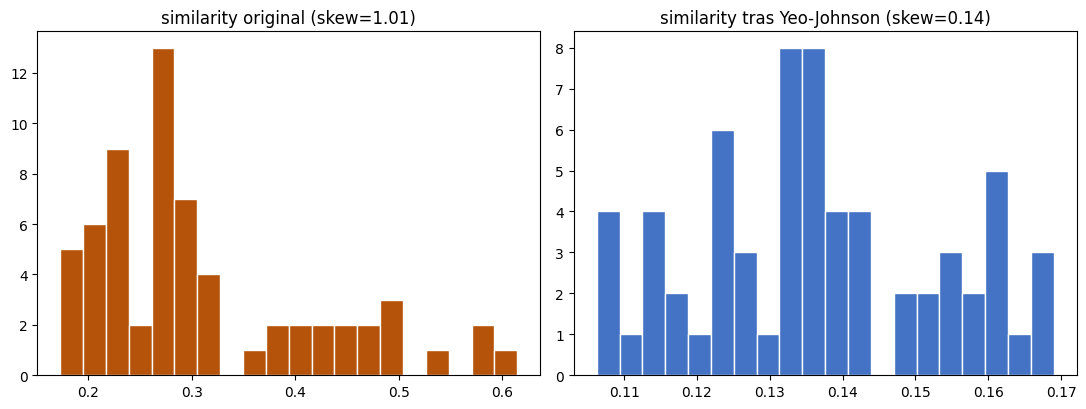


[Figura guardada: similarity antes/después de transformar]

Tabla de características derivadas del pipeline guardada: 64 filas x 31 columnas.


In [10]:
import os
os.environ["MPLCONFIGDIR"] = "/tmp/mpl-fe-threatllm"
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from scipy.stats import skew, yeojohnson
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
import matplotlib
import matplotlib.pyplot as plt

# NOTA: este script se ejecuta DESPUÉS de correr en el mismo namespace las Etapas 1 a 6 del
# pipeline, de las que reutiliza etapa3_report_df (prob_ataque) y matches_enriched_df
# (threat_composite_score, severity_category, primary_tactic, num_tactics, similarity).

print("=== 3.1 Generación de nuevas características — variables derivadas del pipeline ===")
df = matches_enriched_df.copy()
df["is_single_tactic"] = (df["num_tactics"] == 1).astype(int)
df["severity_x_similarity"] = df["threat_composite_score"] * df["similarity"]
print(
    "Se agregan dos características derivadas de segundo orden: 'is_single_tactic' (bandera de "
    "si la técnica pertenece a una sola táctica, útil porque la fórmula de CTS pondera distinto "
    "una técnica con una táctica vs. varias) y 'severity_x_similarity' (producto de la severidad "
    "de la técnica por la confianza de la vinculación semántica —> una técnica de alto CTS "
    "vinculada con baja similitud es un caso de riesgo distinto a uno de alto CTS con alta "
    "similitud, y esta interacción lo distingue en una sola columna)."
)
print(df[["num_tactics", "is_single_tactic", "severity_x_similarity"]].describe().round(3).to_string())

print(f"\nTécnicas con una sola táctica: {int(df['is_single_tactic'].sum())} de {len(df)} pares")

# ---------------------------------------------------------------------------
# 3.2 Codificación
# ---------------------------------------------------------------------------
print("\n=== 3.2 Codificación ===")
n_tactics_cat = df["primary_tactic"].nunique()
print(f"'primary_tactic' tiene {n_tactics_cat} categorías observadas -> ONE-HOT (nominal, sin "
      "orden natural entre tácticas).")
ohe = OneHotEncoder(sparse_output=False, dtype=int)
tactic_onehot = ohe.fit_transform(df[["primary_tactic"]])
tactic_onehot_df = pd.DataFrame(tactic_onehot, columns=[f"tact_{c}" for c in ohe.categories_[0]])
print(f"Columnas binarias generadas: {list(tactic_onehot_df.columns)}")

SEVERITY_ORDER = ["Bajo", "Medio", "Alto", "Crítico"]
print(
    f"\n'severity_category' SÍ tiene un orden natural ({' < '.join(SEVERITY_ORDER)}, ya "
    "discretizado por el propio pipeline en la Etapa 5 a partir de threat_composite_score) -> "
    "ORDINAL, no one-hot. Usar one-hot aquí descartaría a propósito la información de orden que "
    "la propia fórmula de CTS ya construyó; un ordinal explícito (no alfabético) la conserva."
)
ord_enc = OrdinalEncoder(categories=[SEVERITY_ORDER])
df["severity_ordinal"] = ord_enc.fit_transform(df[["severity_category"]].astype(str))
print(df[["severity_category", "severity_ordinal"]].drop_duplicates().sort_values("severity_ordinal").to_string(index=False))

df = pd.concat([df, tactic_onehot_df], axis=1)

# ---------------------------------------------------------------------------
# 3.3 Escalamiento
# ---------------------------------------------------------------------------
print("\n=== 3.3 Escalamiento ===")
NUM_FEATS_3 = ["similarity", "threat_composite_score", "num_tactics", "severity_x_similarity"]
print(
    "threat_composite_score vive en una escala acotada ([0,1] por diseño de la Etapa 5) pero "
    "num_tactics es un conteo entero pequeño (1 a 2 en esta muestra). Es decir, son escalas distintas que, combinadas en un "
    "único vector de entrada para un modelo de triage, sesgarían la distancia/el gradiente hacia "
    "la variable de mayor magnitud relativa igual que en la Parte 1. Se aplica StandardScaler, "
    "consistente con la elección ya justificada para sentence_classification. El escalador se ajusta sobre "
    "los pares disponibles porque esta tabla no tiene partición train/dev/test (análisis descriptivo, no entrenamiento)."
)
scaler = StandardScaler()
scaled = scaler.fit_transform(df[NUM_FEATS_3])
scaled_df = pd.DataFrame(scaled, columns=[f"{c}_std" for c in NUM_FEATS_3])
print("\nAntes de escalar:")
print(df[NUM_FEATS_3].describe().round(3).to_string())
print("\nDespués de StandardScaler (media≈0, desv≈1):")
print(scaled_df.describe().round(3).to_string())
df = pd.concat([df, scaled_df], axis=1)

# ---------------------------------------------------------------------------
# 3.4 Transformación
# ---------------------------------------------------------------------------
print("\n=== 3.4 Transformación ===")
skew_before = df[NUM_FEATS_3].apply(lambda c: skew(c.astype(float)))
print("Sesgo antes de transformar:")
print(skew_before.round(3).to_string())

for c in NUM_FEATS_3:
    if abs(skew_before[c]) > 0.75:
        yj_vals, lam = yeojohnson(df[c].to_numpy(dtype=float))
        df[f"{c}_yj"] = yj_vals
        print(f"  {c:24s}: sesgo {skew_before[c]:+.3f} -> {skew(yj_vals):+.3f} tras Yeo-Johnson (λ={lam:.3f})")
    else:
        print(f"  {c:24s}: sesgo {skew_before[c]:+.3f} -> dentro de rango aceptable, no se transforma")

print(
    "\nNota: 'num_tactics' toma muy pocos valores distintos (1 a 2 en esta muestra), "
    "una transformación continua como Yeo-Johnson tiene poco efecto práctico sobre una variable "
    "casi categórica; se mantiene aquí por completitud metodológica, pero en la fase de modelado "
    "probablemente convenga tratarla como categórica ordinal en vez de numérica continua."
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(df["similarity"], bins=20, color="#B45309", edgecolor="white")
axes[0].set_title(f"similarity original (skew={skew_before['similarity']:.2f})")
if "similarity_yj" in df.columns:
    axes[1].hist(df["similarity_yj"], bins=20, color="#4472C4", edgecolor="white")
    axes[1].set_title(f"similarity tras Yeo-Johnson (skew={skew(df['similarity_yj']):.2f})")
else:
    axes[1].hist(df["similarity_std"], bins=20, color="#4472C4", edgecolor="white")
    axes[1].set_title("similarity tras StandardScaler")
plt.tight_layout()
plt.savefig("fe3_derivadas.png", dpi=110)
plt.show()
print("\n[Figura guardada: similarity antes/después de transformar]")

df.to_csv("feat_derivadas.csv", index=False)
print(f"\nTabla de características derivadas del pipeline guardada: {df.shape[0]} filas x {df.shape[1]} columnas.")


**Síntesis de la Parte 3.**

Se generaron `is_single_tactic` (bandera) y `severity_x_similarity` (interacción de
severidad por confianza de vinculación).

`primary_tactic` (8 categorías observadas, sin orden) se codificó con
one-hot; `severity_category` (que SÍ tiene orden — Bajo < Medio < Alto < Crítico — y la construye la Etapa 5 a
partir de `threat_composite_score`) se codificó con un **ordinal explícito**, no alfabético, para conservar ese
orden.

Las variables numéricas (`similarity`, `threat_composite_score`, `num_tactics`, la interacción) se
escalaron con `StandardScaler` por la misma razón que en la Parte 1.


Al transformar, `similarity` (sesgo +1.01) y `severity_x_similarity` (+1.08) superaron el umbral de 0.75 y se corrigieron con Yeo-Johnson (sesgo residual +0.14 y +0.11), aunque con valores de λ extremos (−5.5 y −6.5) y solo 64 observaciones, lo que hace la transformación inestable.

`threat_composite_score` (+0.00) y num_tactics (+0.73) quedaron dentro de rango y no se transformaron. `num_tactics` toma solo los valores {1, 2}, es decir, es casi categórica, y en el modelado convendría tratarla como ordinal.


## Parte 4 — Selección y extracción de características

Con las características de las Partes 1-3 ya generadas (siguen disponibles en este notebook: la
ejecución es secuencial, igual que en cualquier notebook real), se aplican y justifican los
métodos de filtrado y extracción solicitados: **umbral de varianza**, **correlación**,
**Chi-cuadrado**, **ANOVA**, **PCA** y **Análisis Factorial**. El objetivo, como indican las
instrucciones, es reducir almacenamiento, complejidad del modelo y tiempo de entrenamiento.

**Alcance del experimento.**

La selección se evalúa sobre el TF-IDF de palabras porque es la representación que produce la Etapa 2 del pipeline y la única en la que cada columna es un término interpretable (necesario para chi-cuadrado y para analizar la dirección de los términos). Mantener fijos la representación y el clasificador permite atribuir las diferencias de rendimiento únicamente al método de selección.

El clasificador final de la Etapa 3 (make_aux_logreg, Parte 3) usa n-gramas de caracteres (char_wb, de 3 a 6): en lugar de contar palabras completas, cuenta fragmentos de 3 a 6 letras consecutivas (por ejemplo, mal, alw, ware dentro de malware). Es un espacio de características distinto, por lo que los términos y reducciones seleccionados aquí no se trasladan directamente a él: los resultados indican qué señales y qué reducciones son razonables, no el rendimiento que tendría el modelo final con ellas.

Replicar el experimento sobre n-gramas de caracteres queda como trabajo para la fase de modelado.

=== 4.1 Selección por umbral de varianza — sobre la matriz TF-IDF (7,715 términos) ===
Objetivo: reducir almacenamiento/complejidad eliminando columnas del vocabulario que casi no varían entre oraciones (términos tan raros o tan uniformes que aportan poca información discriminativa a un clasificador lineal).
  umbral=0.0     : conserva 7715 de 7715 términos (100.0%)
  umbral=1e-05   : conserva 7715 de 7715 términos (100.0%)
  umbral=0.0001  : conserva 2723 de 7715 términos (35.3%)

Con umbral=1e-4 se descartan 4992 términos. Ejemplos de términos descartados (aparecen en muy pocas oraciones de train, por lo que su varianza es casi nula): ['000 times', '10 and', '12 months', '16', '17', '18th', '19 vaccination', '2011', '2011 to', '2013', '2015 the', '2016 and']

Justificación del umbral elegido (1e-4, no 0): un umbral de 0 solo elimina columnas exactamente constantes (en TF-IDF, casi ninguna lo es), así que no reduce nada en la práctica. Con 1e-4 se eliminan los términos más raros (pres

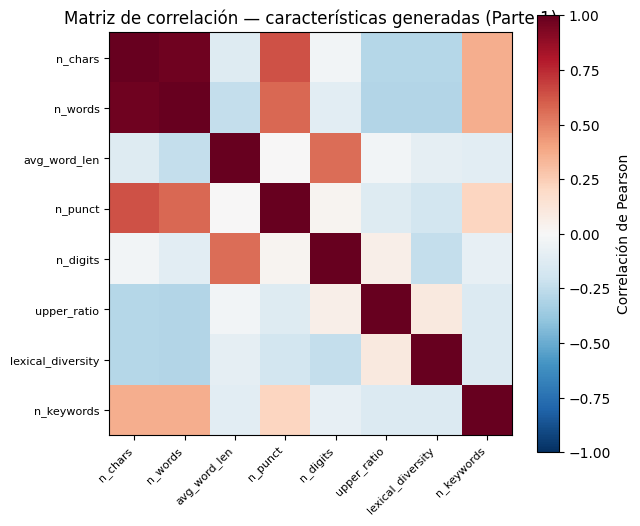


[Figura guardada: mapa de calor de correlación]

=== 4.3 Selección por Chi-cuadrado — términos TF-IDF vs. label ===
Chi-cuadrado es el método estándar de selección de características para texto representado con conteos/TF-IDF no negativos (a diferencia de ANOVA o correlación de Pearson, no asume normalidad y funciona bien sobre matrices dispersas).

Top 20 términos por score de Chi-cuadrado (mayor score = más asociado con la etiqueta):
  chi2=   12.56  'com'
  chi2=   11.89  'device'
  chi2=   10.30  'contacts'
  chi2=    9.53  'send'
  chi2=    9.20  'sms'
  chi2=    8.35  'specified'
  chi2=    8.22  'information'
  chi2=    8.10  'messages'
  chi2=    7.52  'record'
  chi2=    7.02  'location'
  chi2=    6.82  'the device'
  chi2=    6.72  'screen'
  chi2=    6.69  'calls'
  chi2=    5.92  'user'
  chi2=    5.44  'victim'
  chi2=    5.43  'collect'
  chi2=    5.39  'stealing'
  chi2=    5.38  'phone'
  chi2=    5.37  'audio'
  chi2=    5.36  'the victim'

Nota: chi-cuadrado mide qu

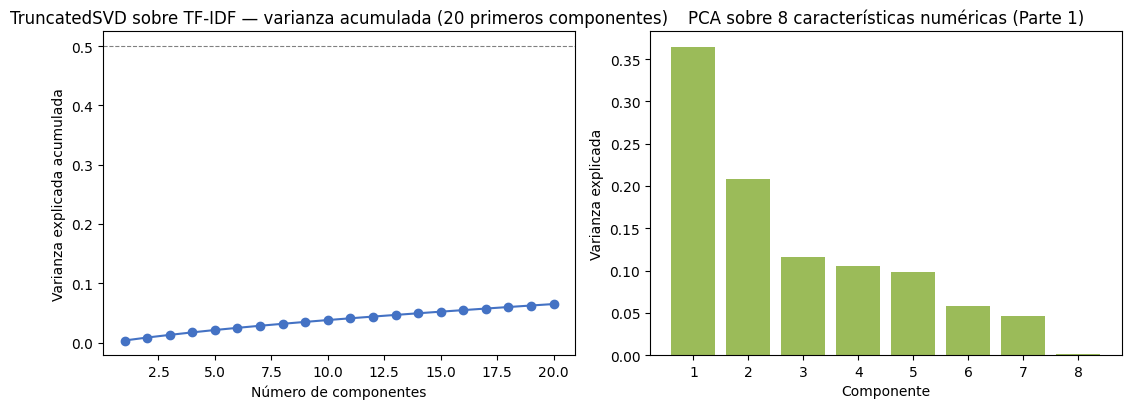


[Figura guardada: varianza explicada — TruncatedSVD (TF-IDF) y PCA (numéricas)]

=== 4.6 Extracción de características — Análisis Factorial (FA) ===
A diferencia de PCA (que busca ejes de máxima varianza, sin distinguir señal de ruido), el Análisis Factorial asume que las características observadas son generadas por un número menor de factores latentes más ruido específico de cada variable; un marco más apropiado si se sospecha que, p. ej., 'n_chars', 'n_words' y 'n_punct' podrían ser manifestaciones superficiales de un único factor latente de 'verbosidad' de la oración.

Cargas factoriales (loadings) de cada característica sobre los 2 factores extraídos:
                   Factor_1  Factor_2
n_chars               0.999     0.012
n_words               0.979    -0.120
avg_word_len         -0.140     0.830
n_punct               0.633     0.143
n_digits             -0.033     0.671
upper_ratio          -0.290    -0.020
lexical_diversity    -0.284    -0.162
n_keywords            0.362    

In [11]:
import os
os.environ["MPLCONFIGDIR"] = "/tmp/mpl-fe-threatllm"
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from sklearn.feature_selection import VarianceThreshold, SelectKBest, chi2, f_classif
from sklearn.decomposition import PCA, TruncatedSVD, FactorAnalysis
import matplotlib
import matplotlib.pyplot as plt

# NOTA: este script se ejecuta DESPUÉS de etapa1_code.py, etapa2_code.py (X_train, y_train,
# tfidf, feature_names) y fe1_sentence_classification.py (feat_df con las 8 características
# numéricas generadas en la Parte 1, columnas NUM_FEATS).

print(f"=== 4.1 Selección por umbral de varianza — sobre la matriz TF-IDF ({X_train.shape[1]:,} términos) ===")
print(
    "Objetivo: reducir almacenamiento/complejidad eliminando columnas del vocabulario que casi "
    "no varían entre oraciones (términos tan raros o tan uniformes que aportan poca información "
    "discriminativa a un clasificador lineal)."
)
for thr in [0.0, 1e-5, 1e-4]:
    vt = VarianceThreshold(threshold=thr)
    vt.fit(X_train)
    n_keep = vt.get_support().sum()
    print(f"  umbral={thr:<8}: conserva {n_keep} de {X_train.shape[1]} términos "
          f"({n_keep / X_train.shape[1]:.1%})")

vt_final = VarianceThreshold(threshold=1e-4)
X_train_vt = vt_final.fit_transform(X_train)
removed_terms = [f for f, keep in zip(feature_names, vt_final.get_support()) if not keep]
print(f"\nCon umbral=1e-4 se descartan {len(removed_terms)} términos. Ejemplos de términos descartados "
      f"(aparecen en muy pocas oraciones de train, por lo que su varianza es casi nula): {removed_terms[:12]}")
print(
    "\nJustificación del umbral elegido (1e-4, no 0): un umbral de 0 solo elimina columnas exactamente "
    "constantes (en TF-IDF, casi ninguna lo es), así que no reduce nada en la práctica. Con 1e-4 se "
    "eliminan los términos más raros (presentes en 8 o menos oraciones de train, mediana 2), que aportan "
    "poca información generalizable a un clasificador. Como el vocabulario de TTPs tiene cola larga (ver EDA "
    "del Avance 1), este umbral es agresivo (descarta cerca de dos tercios del vocabulario), por lo que su "
    "efecto sobre el rendimiento se verifica empíricamente en 4.7 y 4.8."
)


# ---------------------------------------------------------------------------
# 4.2 Correlación — entre las características numéricas generadas en la Parte 1
# ---------------------------------------------------------------------------
print("\n=== 4.2 Selección por correlación — características numéricas de la Parte 1 ===")
corr = feat_df[NUM_FEATS].corr()
print(corr.round(2).to_string())

corr_pairs = []
for i, a in enumerate(NUM_FEATS):
    for b in NUM_FEATS[i + 1:]:
        corr_pairs.append((a, b, corr.loc[a, b]))
corr_pairs.sort(key=lambda t: abs(t[2]), reverse=True)
print("\nPares más correlacionados (|r| > 0.6, candidatos a redundancia):")
redundantes = [p for p in corr_pairs if abs(p[2]) > 0.6]
for a, b, r in redundantes:
    print(f"  {a} <-> {b}: r = {r:+.3f}")

print(
    "\nDecisión: 'n_chars' y 'n_words' están altamente correlacionadas (redundancia esperada: "
    "ambas miden longitud, una en caracteres y otra en palabras) -> se recomienda conservar solo "
    "una (n_words, más interpretable y menos sensible a la longitud de palabras individuales) "
    "antes de entrenar un modelo, en vez de alimentarle dos columnas casi idénticas que inflan "
    "la matriz de entrada sin aportar información nueva."
)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_FEATS)))
ax.set_xticklabels(NUM_FEATS, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(NUM_FEATS)))
ax.set_yticklabels(NUM_FEATS, fontsize=8)
plt.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Matriz de correlación — características generadas (Parte 1)")
plt.tight_layout()
plt.savefig("fe4_correlacion.png", dpi=110)
plt.show()
print("\n[Figura guardada: mapa de calor de correlación]")

# ---------------------------------------------------------------------------
# 4.3 Chi-cuadrado — sobre TF-IDF (texto) vs. etiqueta
# ---------------------------------------------------------------------------
print("\n=== 4.3 Selección por Chi-cuadrado — términos TF-IDF vs. label ===")
print(
    "Chi-cuadrado es el método estándar de selección de características para texto representado "
    "con conteos/TF-IDF no negativos (a diferencia de ANOVA o correlación de Pearson, no asume "
    "normalidad y funciona bien sobre matrices dispersas)."
)
skb_chi2 = SelectKBest(chi2, k=20)
skb_chi2.fit(X_train, y_train)
scores = skb_chi2.scores_
top20_idx = np.argsort(scores)[-20:][::-1]
print("\nTop 20 términos por score de Chi-cuadrado (mayor score = más asociado con la etiqueta):")
for idx in top20_idx:
    print(f"  chi2={scores[idx]:8.2f}  {feature_names[idx]!r}")
print(
    "\nNota: chi-cuadrado mide qué tanto un término separa las clases, no hacia cuál de ellas; la dirección "
    "(clase en la que domina cada término) se verifica en 4.7. Además, LADDER proviene de reportes de malware "
    "móvil, por lo que el vocabulario seleccionado (device, contacts, sms, ...) refleja ese dominio y puede "
    "no generalizar a otros tipos de ataque."
)

# ---------------------------------------------------------------------------
# 4.4 ANOVA F-test — sobre las características numéricas de la Parte 1
# ---------------------------------------------------------------------------
print("\n=== 4.4 Selección por ANOVA (F-test) — características numéricas vs. label ===")
print(
    "ANOVA (f_classif) es apropiado aquí porque las 8 características de la Parte 1 son "
    "numéricas continuas y la variable objetivo es categórica binaria — exactamente el escenario "
    "para el que está diseñada esta prueba (a diferencia de chi2, que requiere conteos no "
    "negativos tipo texto, no features continuas como avg_word_len)."
)
f_scores, p_values = f_classif(feat_df[NUM_FEATS], feat_df["label"])
anova_df = pd.DataFrame({"feature": NUM_FEATS, "F": f_scores, "p_value": p_values}).sort_values(
    "F", ascending=False
)
print(anova_df.round(4).to_string(index=False))
sig = anova_df[anova_df["p_value"] < 0.05]
print(f"\nCaracterísticas estadísticamente significativas (p < 0.05): {len(sig)} de {len(NUM_FEATS)} "
      f"-> {sig['feature'].tolist()}")
bonf = 0.05 / len(NUM_FEATS)
sig_b = anova_df[anova_df["p_value"] < bonf]["feature"].tolist()
print(f"Con corrección de Bonferroni (alfa = 0.05/{len(NUM_FEATS)} = {bonf:.4f}) quedan significativas "
      f"{len(sig_b)} de {len(NUM_FEATS)}: {sig_b}")
print(
    f"\nLas tres características con mayor F son {anova_df['feature'].head(3).tolist()}. n_keywords destaca "
    "con mucha ventaja y también era la más correlacionada con la etiqueta en 1.1, así que dos pruebas "
    "distintas coinciden en señalarla como la más útil; n_digits y n_chars siguen con F mucho menor y "
    "lexical_diversity no es significativa. Precauciones: ANOVA asume distribuciones aproximadamente "
    "normales y varias de estas características están muy sesgadas (ver 1.5), y n_keywords usa una lista "
    "definida por el equipo, por lo que su ventaja es en parte esperable por construcción."
)


# ---------------------------------------------------------------------------
# 4.5 PCA / reducción de dimensionalidad
# ---------------------------------------------------------------------------
print("\n=== 4.5 Extracción de características — PCA ===")
print(
    "Nota metodológica: PCA clásico (sklearn.decomposition.PCA) centra los datos "
    "restando la media, lo que para una matriz TF-IDF dispersa de 7,715 columnas densificaría toda la matriz en memoria (2214 x 7715 flotantes ≈ 137 MB solo para train,"
    " antes de cualquier copia intermedia) sin necesidad real. Por eso, para la matriz TF-IDF se usa "
    "TruncatedSVD (el equivalente estándar de PCA para datos dispersos, sin centrar, que "
    "scikit-learn recomienda explícitamente para este caso) y se aplica PCA literal sobre las 8 "
    "características numéricas de la Parte 1, donde sí es barato densificar."
)
svd = TruncatedSVD(n_components=50, random_state=42)
X_train_svd = svd.fit_transform(X_train)
var_exp_svd = svd.explained_variance_ratio_
print(f"\nTruncatedSVD sobre TF-IDF: 50 componentes explican {var_exp_svd.sum():.1%} de la "
      f"varianza total (de {X_train.shape[1]} columnas originales).")
print(f"Primeros 5 componentes, varianza explicada individual: "
      f"{[round(float(v), 4) for v in var_exp_svd[:5]]}")
print(
    "Nota: 12.7% es poco — la varianza de TF-IDF está muy repartida entre los 7715 "
    "términos (consistente con el vocabulario de cola larga ya visto en la EDA), así que capturar "
    "una fracción sustancial requeriría cientos de componentes, no 50. En el experimento 4.7, con "
    "dimensiones comparables, TruncatedSVD TruncatedSVD tiende a conservar más rendimiento que la selección por Chi-cuadrado"
    "que la selección por Chi-cuadrado, "
    "mientras que Chi-cuadrado ofrece características interpretables (términos reales); la elección "
    "depende de si se prioriza rendimiento o interpretabilidad."
)


pca_num = PCA(n_components=NUM_FEATS.__len__())
pca_scores = pca_num.fit_transform(feat_df[[f"{c}_std" for c in NUM_FEATS]])
var_exp_num = pca_num.explained_variance_ratio_
print(f"\nPCA literal sobre las 8 características numéricas ya escaladas (StandardScaler, "
      f"Parte 1.4): varianza explicada por componente: {[round(float(v), 4) for v in var_exp_num]}")
n_comp_90 = int(np.argmax(np.cumsum(var_exp_num) >= 0.90) + 1)
print(f"Se necesitan {n_comp_90} componentes para explicar >=90% de la varianza de estas 8 "
      f"características (de 8 originales) -> reducción modesta, esperable porque ya se detectó "
      f"en 4.2 que solo un par (n_chars/n_words) es redundante; el resto aporta varianza propia.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(range(1, 21), np.cumsum(var_exp_svd[:20]), marker="o", color="#4472C4")
axes[0].set_title("TruncatedSVD sobre TF-IDF — varianza acumulada (20 primeros componentes)")
axes[0].set_xlabel("Número de componentes")
axes[0].set_ylabel("Varianza explicada acumulada")
axes[0].axhline(0.5, color="gray", linestyle="--", linewidth=0.8)

axes[1].bar(range(1, len(var_exp_num) + 1), var_exp_num, color="#9BBB59")
axes[1].set_title("PCA sobre 8 características numéricas (Parte 1)")
axes[1].set_xlabel("Componente")
axes[1].set_ylabel("Varianza explicada")
plt.tight_layout()
plt.savefig("fe4_pca.png", dpi=110)
plt.show()
print("\n[Figura guardada: varianza explicada — TruncatedSVD (TF-IDF) y PCA (numéricas)]")

# ---------------------------------------------------------------------------
# 4.6 Análisis Factorial (FA)
# ---------------------------------------------------------------------------
print("\n=== 4.6 Extracción de características — Análisis Factorial (FA) ===")
print(
    "A diferencia de PCA (que busca ejes de máxima varianza, sin distinguir señal de ruido), el "
    "Análisis Factorial asume que las características observadas son generadas por un número "
    "menor de factores latentes más ruido específico de cada variable; un marco más apropiado "
    "si se sospecha que, p. ej., 'n_chars', 'n_words' y 'n_punct' podrían ser manifestaciones "
    "superficiales de un único factor latente de 'verbosidad' de la oración."
)
fa = FactorAnalysis(n_components=2, random_state=42)
fa.fit(feat_df[[f"{c}_std" for c in NUM_FEATS]])
loadings = pd.DataFrame(
    fa.components_.T, index=NUM_FEATS, columns=["Factor_1", "Factor_2"]
)
print("\nCargas factoriales (loadings) de cada característica sobre los 2 factores extraídos:")
print(loadings.round(3).to_string())
print(
    "\nInterpretación: Factor_1 carga fuerte en n_chars (0.999), n_words (0.979) y n_punct (0.633) -> factor de "
    "'longitud/verbosidad' de la oración. Factor_2 carga en avg_word_len (0.830) y n_digits (0.671) -> factor de "
    "'palabras largas con dígitos', posiblemente asociado a identificadores técnicos (hashes, IPs, versiones, "
    "nombres de archivo). upper_ratio, lexical_diversity y n_keywords cargan débilmente en ambos factores, por "
    "lo que aportan información propia que estos dos factores no capturan. Se eligen 2 factores por el criterio "
    "de Kaiser: solo dos autovalores de la matriz de correlación superan 1 (aprox. 2.92 y 1.67). Los resultados "
    "confirman, con un método distinto a PCA, que hay al menos dos fuentes de variación independientes detrás de "
    "las 8 características. Nota: n_chars y n_words son casi colineales (r=0.976), lo que vuelve numéricamente "
    "frágil la carga de n_chars (0.999)."
)


print(
    "\n=== Resumen 4 — qué método de selección/extracción se usaría en la práctica, y por qué ==="
)
resumen = pd.DataFrame([
    {"Método": "Umbral de varianza", "Aplicado a": f"TF-IDF ({X_train.shape[1]:,} términos)", "Resultado": f"descarta {len(removed_terms)} términos muy raros con umbral=1e-4; sin diferencia significativa de accuracy en dev (4.7-4.8)"},
    {"Método": "Correlación", "Aplicado a": "8 características numéricas (Parte 1)", "Resultado": "n_chars/n_words redundantes (r>0.6) -> conservar solo una"},
    {"Método": "Chi-cuadrado", "Aplicado a": "TF-IDF vs. label", "Resultado": "20 términos que más separan las clases (19 dominan en ataque; 'com' domina en no ataque); vocabulario de malware móvil"},
    {"Método": "ANOVA (F-test)", "Aplicado a": "8 características numéricas vs. label", "Resultado": "n_keywords destaca; luego n_digits y n_chars; lexical_diversity no es significativa"},
    {"Método": "PCA / TruncatedSVD", "Aplicado a": "TF-IDF (SVD) y 8 numéricas (PCA)", "Resultado": "50 componentes SVD capturan solo ~13% de la varianza de TF-IDF (muy repartida en 7715 términos); las 8 numéricas sí se comprimen razonablemente (6 componentes para 90%)"},
    {"Método": "Análisis Factorial", "Aplicado a": "8 características numéricas (Parte 1)", "Resultado": "2 factores: 'longitud' (n_chars, n_words, n_punct) y 'palabras largas con dígitos' (avg_word_len, n_digits)"},
])
print(resumen.to_string(index=False))


### 4.7 - 4.8: Experimento de selección: comparación empírica de métodos

Hasta aquí cada método se aplicó por separado. Aquí se comparan sobre la misma representación (TF-IDF de palabras) y el mismo clasificador, ajustando cada selector solo con train y evaluando en dev. Es una guía orientativa: el clasificador final de la Etapa 3 usa n-gramas de caracteres, por lo que estos resultados no se aplican directamente a él.

In [12]:
# ===========================================================================
# 4.7 Experimento de selección: ¿qué método conserva (o mejora) el rendimiento?
# Misma representación (TF-IDF de palabras de la Parte 1) y mismo clasificador
# (LogisticRegression) para todos; el selector se AJUSTA SOLO CON TRAIN y se evalúa en DEV.
# Test no se toca. Es una comparación orientativa, no el modelo final (que usa n-gramas de caracteres).
# ===========================================================================
import numpy as np, pandas as pd, re
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, chi2, VarianceThreshold
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

def _num_feats(df):
    out = pd.DataFrame(index=df.index)
    t = df["text"]
    out["n_chars"] = t.str.len()
    out["n_words"] = t.str.split().apply(len)
    out["avg_word_len"] = out["n_chars"] / out["n_words"]
    out["n_punct"] = t.apply(contar_puntuacion)
    out["n_digits"] = t.apply(lambda s: sum(ch.isdigit() for ch in s))
    out["upper_ratio"] = t.apply(lambda s: sum(1 for ch in s if ch.isupper()) / max(len(s), 1))
    out["lexical_diversity"] = t.apply(lambda s: len(set(re.findall(r"[a-záéíóúñ]+", s.lower())))
                                       / max(len(re.findall(r"[a-záéíóúñ]+", s.lower())), 1))
    out["n_keywords"] = t.apply(contar_keywords)
    return out[NUM_FEATS]

N_tr, N_dev = _num_feats(train_df), _num_feats(dev_df)
sc = StandardScaler().fit(N_tr)                     # fit SOLO con train
Ntr_s, Ndev_s = sc.transform(N_tr), sc.transform(N_dev)  # dev solo con transform
sin_nchars = [i for i, c in enumerate(NUM_FEATS) if c != "n_chars"]

def evalua(nombre, Xtr, Xdev):
    clf = LogisticRegression(max_iter=2000, solver="liblinear", random_state=42)
    clf.fit(Xtr, y_train)
    p = clf.predict(Xdev)
    return {"Configuración": nombre, "n_features": Xtr.shape[1],
            "acc_dev": round(accuracy_score(y_dev, p), 4), "f1_dev": round(f1_score(y_dev, p), 4)}

filas = [evalua("A. TF-IDF completo", X_train, X_dev)]
vt = VarianceThreshold(1e-4).fit(X_train)
filas.append(evalua("B. Umbral de varianza 1e-4", vt.transform(X_train), vt.transform(X_dev)))
for k in (100, 300, 1000):
    sk = SelectKBest(chi2, k=k).fit(X_train, y_train)
    filas.append(evalua(f"C. Chi² top-{k}", sk.transform(X_train), sk.transform(X_dev)))
for n in (50, 300):
    svd = TruncatedSVD(n_components=n, random_state=42).fit(X_train)
    filas.append(evalua(f"D. TruncatedSVD-{n}", svd.transform(X_train), svd.transform(X_dev)))
filas.append(evalua("E. Solo 8 numéricas", Ntr_s, Ndev_s))
filas.append(evalua("F. Solo 7 numéricas (sin n_chars)", Ntr_s[:, sin_nchars], Ndev_s[:, sin_nchars]))
sk1000 = SelectKBest(chi2, k=1000).fit(X_train, y_train)
filas.append(evalua("G. Chi² top-1000 + 7 numéricas",
                    sparse.hstack([sk1000.transform(X_train), sparse.csr_matrix(Ntr_s[:, sin_nchars])]).tocsr(),
                    sparse.hstack([sk1000.transform(X_dev), sparse.csr_matrix(Ndev_s[:, sin_nchars])]).tocsr()))
filas.append(evalua("H. TF-IDF completo + 7 numéricas",
                    sparse.hstack([X_train, sparse.csr_matrix(Ntr_s[:, sin_nchars])]).tocsr(),
                    sparse.hstack([X_dev, sparse.csr_matrix(Ndev_s[:, sin_nchars])]).tocsr()))
res = pd.DataFrame(filas)
print("=== 4.7 Experimento de selección (LogisticRegression, evaluación en DEV) ===")
print(res.to_string(index=False))

# Dirección de los términos de chi² (chi² no la indica): proporción de oraciones que contienen el término
vocab = np.array(tfidf.get_feature_names_out())
sk20 = SelectKBest(chi2, k=20).fit(X_train, y_train)
idx = np.argsort(sk20.scores_)[::-1][:20]
B = (X_train > 0).tocsc()
pos, neg = (y_train == 1), (y_train == 0)
dir_rows = []
for j in idx:
    col = B[:, j].toarray().ravel()
    p1, p0 = col[pos].mean(), col[neg].mean()
    dir_rows.append({"término": vocab[j], "chi2": round(sk20.scores_[j], 2),
                     "% en ataque": round(100 * p1, 1), "% en no ataque": round(100 * p0, 1),
                     "clase dominante": "ataque" if p1 > p0 else "no ataque"})
print("\nDirección de los 20 términos con mayor chi² (porcentaje de oraciones de train que los contienen):")
print(pd.DataFrame(dir_rows).to_string(index=False))


=== 4.7 Experimento de selección (LogisticRegression, evaluación en DEV) ===
                    Configuración  n_features  acc_dev  f1_dev
               A. TF-IDF completo        7715   0.7746  0.7762
       B. Umbral de varianza 1e-4        2723   0.7729  0.7757
                  C. Chi² top-100         100   0.7201  0.7028
                  C. Chi² top-300         300   0.7394  0.7289
                 C. Chi² top-1000        1000   0.7553  0.7566
               D. TruncatedSVD-50          50   0.7342  0.7308
              D. TruncatedSVD-300         300   0.7641  0.7633
              E. Solo 8 numéricas           8   0.6180  0.5989
F. Solo 7 numéricas (sin n_chars)           7   0.6215  0.5996
   G. Chi² top-1000 + 7 numéricas        1007   0.7482  0.7423
 H. TF-IDF completo + 7 numéricas        7722   0.7606  0.7491

Dirección de los 20 términos con mayor chi² (porcentaje de oraciones de train que los contienen):
    término  chi2  % en ataque  % en no ataque clase dominante
     

In [13]:
# 4.8 ¿La diferencia entre A (completo) y B (umbral de varianza) es real o ruido?
from scipy.stats import binomtest
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
mk = lambda: LogisticRegression(max_iter=2000, solver="liblinear", random_state=42)
pa = mk().fit(X_train, y_train).predict(X_dev)
vt48 = VarianceThreshold(1e-4).fit(X_train)
pb = mk().fit(vt48.transform(X_train), y_train).predict(vt48.transform(X_dev))
ca, cb = (pa == y_dev), (pb == y_dev)
b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())
print("=== 4.8 Contraste estadístico: TF-IDF completo (A) vs. umbral de varianza (B) ===")
print(f"dev: n={len(y_dev)}; margen aproximado (IC 95%) de la accuracy = +-{1.96*np.sqrt(0.775*0.225/len(y_dev)):.3f}")
print(f"McNemar (mismas oraciones): A acierta y B falla en {b}; B acierta y A falla en {c}; p = {binomtest(b, b+c, 0.5).pvalue:.3f}")
skf = StratifiedKFold(5, shuffle=True, random_state=42)
def cv(sel):
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), max_features=10_000, sublinear_tf=True,
                                         min_df=2, strip_accents="unicode"), *sel, mk())
    s = cross_val_score(pipe, train_df["text"], y_train, cv=skf)
    return f"{s.mean():.4f} +- {s.std():.4f}"
print("Validación cruzada 5-fold sobre train, accuracy:")
print("  A. completo         :", cv([]))
print("  B. varianza 1e-4    :", cv([VarianceThreshold(1e-4)]))
print("  C. chi2 top-1000    :", cv([SelectKBest(chi2, k=1000)]))


=== 4.8 Contraste estadístico: TF-IDF completo (A) vs. umbral de varianza (B) ===
dev: n=568; margen aproximado (IC 95%) de la accuracy = +-0.034
McNemar (mismas oraciones): A acierta y B falla en 7; B acierta y A falla en 6; p = 1.000
Validación cruzada 5-fold sobre train, accuracy:
  A. completo         : 0.8288 +- 0.0188
  B. varianza 1e-4    : 0.8207 +- 0.0175
  C. chi2 top-1000    : 0.8175 +- 0.0174


In [14]:
# ¿El umbral de varianza elimina términos valiosos?
from sklearn.feature_selection import chi2
names = np.array(tfidf.get_feature_names_out())
keep = vt_final.get_support()
sc, _ = chi2(X_train, y_train); sc = np.nan_to_num(sc)
kw_en_vocab = sorted(k for k in KEYWORDS if k in set(names))
print("KEYWORDS eliminadas por varianza:", [k for k in kw_en_vocab if not keep[list(names).index(k)]])
order = np.argsort(-sc)
for k in (20, 100, 500):
    print(f"de los top-{k} por chi2, eliminados por varianza:", int((~keep[order[:k]]).sum()))
print(f"chi2 máximo entre los términos eliminados: {sc[~keep].max():.2f} (máximo global: {sc.max():.2f})")

KEYWORDS eliminadas por varianza: ['encrypt', 'escalate', 'inject']
de los top-20 por chi2, eliminados por varianza: 0
de los top-100 por chi2, eliminados por varianza: 0
de los top-500 por chi2, eliminados por varianza: 2
chi2 máximo entre los términos eliminados: 1.31 (máximo global: 12.56)


**Resultados de los experimentos 4.7 y 4.8**

(LogisticRegression sobre TF-IDF de palabras; cada selector se ajusta solo con
train y se evalúa en dev, de 568 oraciones).

El TF-IDF completo (7,715 términos) alcanza accuracy 0.775. El
umbral de varianza 1e-4 reduce el vocabulario a 2,723 términos (-65%) con accuracy 0.773, sin diferencia
significativa: McNemar p = 1.0 (los modelos discrepan en solo 13 oraciones, 7 contra 6) y validación cruzada de
0.829 +- 0.019 frente a 0.821 +- 0.018, dentro de una desviación estándar.

Chi-cuadrado con 1,000 términos logra
0.755 y con 100 términos 0.720; TruncatedSVD con 50 y 300 componentes logra 0.734 y 0.764,es decir, a dimensiones comparables SVD tiende a conservar más rendimiento que chi-cuadrado (diferencia de unos 2.5 puntos con 300 componentes), aunque este último produce características interpretables (términos reales).

Las 8 características numéricas por sí solas alcanzan 0.618
(sobre el azar, 0.50) pero muy por debajo de TF-IDF, y añadirlas a TF-IDF no mejora el rendimiento (0.761 frente
a 0.775); eliminar `n_chars` no cambia el resultado (0.622 frente a 0.618), lo que respalda quitar la
redundancia `n_chars`/`n_words`. De los 20 términos con mayor chi-cuadrado, 19 dominan en la clase ataque y
`com` domina en no ataque, lo que confirma que chi-cuadrado mide separación y no dirección. Son resultados de una
sola partición dev; diferencias de unos 2 a 3 puntos están dentro del margen de error y no son concluyentes.

La validación cruzada (~ 0.83) es
mayor que la de dev (~0.77), lo que sugiere que dev es más difícil o que la validación cruzada es optimista
al repartir oraciones de un mismo reporte entre folds.


**Síntesis de la Parte 4.**

El umbral de varianza (1e-4) descarta 4,992 de 7,715 términos TF-IDF, principalmente
términos muy raros (presentes en 8 o menos oraciones de train); el experimento 4.7-4.8 muestra que esto no
produce una diferencia significativa de accuracy en dev. La correlación confirma que `n_chars` y `n_words` son
redundantes (r=0.976); se conserva `n_words` por interpretabilidad, y quitar `n_chars` no cambia el resultado.

---

Chi-cuadrado identifica términos que distinguen las clases (`device`, `contacts`, `send`, `sms`, ...), coherentes
con el vocabulario de recolección de datos en dispositivos móviles de donde proviene el corpus; al medir
asociación sin indicar dirección, esta se comprobó con frecuencias por clase (19 de 20 dominan en ataque, `com`
domina en no ataque).

---
ANOVA indica que `n_keywords` es con mucha diferencia la característica más discriminativa
(F=224), seguida de `n_digits` (F=48) y `n_chars` (F=44); `lexical_diversity` no es significativa (p=0.95), y con
la corrección de Bonferroni quedan 5 de 8.

---
TruncatedSVD con 50 componentes captura solo ~13% de la varianza de
TF-IDF; PCA sobre las numéricas requiere 6 de 8 componentes para 90% y su último componente casi nulo refleja
la redundancia `n_chars`/`n_words`.

---
El Análisis Factorial (2 factores, criterio de Kaiser) separa un factor de
longitud/verbosidad (`n_chars`, `n_words`, `n_punct`) de otro de palabras largas con dígitos (`avg_word_len`,
`n_digits`), que podría reflejar identificadores técnicos como hashes, IPs o nombres de archivo.

---
Finalmente, las
características numéricas no mejoran el modelo sobre TF-IDF, y a dimensiones comparables TruncatedSVD tiende a conservar más rendimiento que chi-cuadrado, que en cambio es interpretable.


## Parte 5 — Conclusiones de la fase de Preparación de Datos, en el contexto de CRISP-ML(Q)

CRISP-ML(Q) (*Cross-Industry Standard Process for Machine Learning with Quality assurance*; Studer et al.,
2021) estructura un proyecto de ML en seis fases: comprensión del negocio y de los datos, **ingeniería de
datos** (preparación), ingeniería del modelo, evaluación (aseguramiento de calidad del modelo), despliegue, y
monitoreo y mantenimiento. Este notebook, junto con el Avance 1, cubre la fase de ingeniería de datos de
ThreatLLM.

1. **Punto de partida (comprensión de datos).** El Avance 1 describió las fuentes de datos, sus valores
   faltantes y duplicados (incluidos duplicados en `entity_extraction` y en el reporte real) y la limpieza
   existente en el pipeline.

2. **Construcción y codificación.** Se generaron 8 características numéricas sobre `sentence_classification`, 4
   sobre `attack-pattern-matching-gt` (`n_words`, `n_chars`, `malware_freq`, `label_freq`) y 2 derivadas del
   pipeline (`is_single_tactic`, `severity_x_similarity`). Se discretizó `n_words` en terciles y la frecuencia
   de técnica en tres categorías de rareza (esta última como marcador diagnóstico, no predictor). La
   codificación depende del tipo de variable: one-hot para nominales (`primary_tactic`, `malware`) y ordinal
   explícito para `severity_category`, que tiene orden natural.

3. **Normalización.** `StandardScaler` ajustado solo con train en la Parte 1 para evitar fuga de información (en la Parte 3, descriptiva y sin partición, se ajusta sobre los 64 pares), y
   Yeo-Johnson para las variables con sesgo > 0.75.
   En la Parte 3 se transformaron `similarity` y `severity_x_similarity` (sesgo > 0.75), con valores de λ extremos y solo 64 observaciones.
   En la Parte 1 persiste sesgo residual en `n_digits` (+1.60) y `avg_word_len` (−1.39). Estas transformaciones preparan las variables para un modelado posterior; el clasificador actual usa TF-IDF y no
   las emplea.

4. **Selección y extracción.** Se aplicaron seis métodos: umbral de varianza (7,715 a 2,723 términos),
   correlación (`n_chars`/`n_words`, r=0.976), chi-cuadrado (términos que distinguen las clases, del dominio
   de malware móvil), ANOVA (`n_keywords`, F=224), TruncatedSVD (50 componentes = 12.7% de la varianza) y
   PCA/Análisis Factorial sobre las numéricas (6 componentes para 90%; 2 factores). El experimento 4.7-4.8
   mostró que el umbral de varianza reduce el vocabulario en 65% sin diferencia significativa de accuracy en
   dev (0.773 frente a 0.775; McNemar p=1.0), que las características numéricas no mejoran el modelo sobre
   TF-IDF y que, a dimensiones comparables, TruncatedSVD tiende a conservar más rendimiento.

5. **Aseguramiento de calidad y riesgos (la Q de CRISP-ML(Q)).**
   - *Fuga de información:* el escalado y la selección se ajustan solo con train (salvo la Parte 3, que es descriptiva y no tiene partición); `label_freq` y
     `rareza_tecnica` se calculan con la etiqueta y se usan solo como diagnóstico.
   - *Circularidad:* `severity_category` deriva de `threat_composite_score`; no se usan juntas como predictores.
   - *Validez del CTS:* la fórmula y sus pesos provienen de etapas previas y su validación independiente
     (EWM) está pendiente; aquí se tratan como salidas del pipeline.
   - *Sesgo de corpus:* el vocabulario seleccionado por chi-cuadrado refleja malware móvil y puede no
     generalizar a otros tipos de ataque.
   - *Pares sin evidencia:* 35 de 99 candidatos técnica-oración tenían similitud 0 y se descartan; quedan 64, y 8 de las 33 oraciones marcadas se quedan sin ningún candidato.
   - *Desajuste de representación:* la selección se evaluó sobre TF-IDF de palabras; el clasificador final
     usa n-gramas de caracteres, por lo que los resultados orientan pero no se aplican directamente a él.
   - *Muestra pequeña:* `attack-pattern-matching-gt` tiene 81 filas, con técnicas de una sola muestra, y la
     lista `KEYWORDS` fue definida manualmente por el equipo.

6. **Insumos para la ingeniería del modelo.** Fusionar `n_chars`/`n_words`; usar el umbral de varianza para
   reducir el vocabulario; elegir entre chi-cuadrado (interpretable) y SVD (tiende a conservar más rendimiento a igual tamaño) según el criterio del modelo; tratar `num_tactics` como categórica ordinal; y validar el CTS
   antes de usarlo como etiqueta o criterio.

En conjunto, esta fase deja los datos descritos, transformados y reducidos con criterio explícito, con los
riesgos anteriores documentados para la siguiente fase.


## Referencias



- Studer, S., Bui, T. B., Drescher, C., Hanuschkin, A., Winkler, L., Peters, S., & Zschech, P.
  (2021). *Towards CRISP-ML(Q): A machine learning process model with quality assurance
  methodology*. Machine Learning and Knowledge Extraction, 3(2), 392-413.
- Yeo, I.-K., & Johnson, R. A. (2000). *A new family of power transformations to improve
  normality or symmetry*. Biometrika, 87(4), 954-959.
- Jolliffe, I. T. (2002). *Principal Component Analysis* (2nd ed.). Springer.
- Pedregosa, F., et al. (2011). *Scikit-learn: Machine learning in Python*. Journal of Machine
  Learning Research, 12, 2825-2830. (Documentación de `sklearn.feature_selection`,
  `sklearn.decomposition` y `sklearn.preprocessing` usada directamente en este notebook.)
- Alam, M. T., Bhusal, D., Park, Y., & Rastogi, N. (2023). *Looking beyond IoCs: Automatically extracting attack patterns from external CTI*. RAID 2023. Dataset y splits oficiales de LADDER (github.com/aiforsec/LADDER).
- MITRE Corporation. *Mobile ATT&CK* (catálogo oficial usado en la Parte 3;
  github.com/mitre/cti).
- Avance 1  del equipo  (comprensión de datos y preprocesamiento), que antecede a este notebook.
